# Document Classification v2
## ConvNeXt Tiny + EfficientNetV2-S — baca dataset langsung

Notebook ini menggantikan alur ResNet18 yang berulang dengan satu pipeline:
**data yang sudah ada → audit tersimpan → split tetap → dua model → evaluasi → submission**.

- Tidak perlu mengunggah, menyalin, atau membuat symlink untuk setiap gambar.
- Jika file gambar sudah ada, file itu dipakai langsung. ZIP juga dapat dibaca tanpa ekstraksi.
- Semua source proyek disertakan; tidak perlu script tambahan dari Add Input.
- PyTorch dan torchvision; bobot awal ImageNet-1K resmi, bukan model RVL-CDIP yang berpotensi bocor.
- Skor ditulis setelah training nyata. **Belum ada klaim akurasi Kaggle dari notebook ini.**

**Langkah singkat:** aktifkan GPU → pastikan dataset gambar tersedia → sesuaikan sel pengaturan bila perlu → Run All.
Internet diperlukan untuk download pertama bobot pretrained, kecuali file bobot sudah disediakan lokal.
Untuk kualitas, jalankan kedua model; untuk uji awal atau waktu terbatas, isi `MODELS` dengan satu model dahulu.

Laporan analisis lengkap terdapat di bagian akhir dan pada `README.md` yang dibuat notebook.

### 1. Pengaturan

`DATA_ROOT=None` memprioritaskan folder bersih sesi lama jika masih ada. Jika tidak,
notebook mencari dataset **gambar** di `/kaggle/input`; dataset structural-damage tabular tidak dipilih.
Jika ada beberapa dataset gambar, isi path secara eksplisit. `IMAGE_ROOTS` hanya diperlukan
jika metadata dan gambar berada di lokasi terpisah.

Penyimpanan `/kaggle/working` dari sesi yang telah berakhir tidak otomatis tersedia.
Pasang kembali dataset atau output notebook tersimpan melalui Add Input; tidak perlu menambahkan gambar satu per satu.

In [1]:
from pathlib import Path

PROJECT = (Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()) / 'docvision_v2'
DATA_ROOT = None
IMAGE_ROOTS = []
ALLOW_ZIP_STREAMING = True
REUSE_LEGACY_SPLIT = True
AUDIT_WORKERS = 4
EXPECTED_CLASSES = 16
SPLIT_SEED = 42
VAL_FRACTION = 0.20

MODELS = ['convnext_tiny', 'efficientnet_v2_s']
RUN_TAG = 'v2'
REQUIRE_GPU = True
ENABLE_TRAINING = True
MAX_HOURS_PER_MODEL = None  # misalnya 4.5: jeda setelah epoch; ulang sel training untuk resume

# Contoh untuk GPU kecil: {'batch_size': 4, 'accumulation_steps': 8}
# Jangan mengubah config run yang sudah dimulai. Ganti RUN_TAG untuk eksperimen baru.
COMMON_OVERRIDES = {}
MODEL_OVERRIDES = {
    'convnext_tiny': {},
    'efficientnet_v2_s': {},
}
# Untuk offline, isi masing-masing override:
# {'local_imagenet_weights': '/kaggle/input/NAMA_BOBOT/convnext_tiny-983f1562.pth'}

# Opsional: salinan cache audit v2 dari output tersimpan (file metadata, bukan gambar).
AUDIT_CACHE_SOURCE = None
RUN_SMOKE_TESTS = False

In [2]:
import os
import sys
import importlib
import importlib.util
import shutil

PROJECT = Path(PROJECT).resolve()
if str(PROJECT).startswith('/kaggle/input/'):
    raise ValueError('PROJECT harus berada di /kaggle/working, bukan input read-only.')
PROJECT.mkdir(parents=True, exist_ok=True)
for folder in ['src/docvision_v2', 'scripts', 'tests', 'configs', 'reports', 'data/splits', 'outputs']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
required = {'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy',
            'pandas': 'pandas', 'PIL': 'Pillow', 'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise RuntimeError(f'Paket belum tersedia: {missing}. Gunakan runtime Kaggle standar; jangan mengganti pasangan torch/torchvision sembarangan.')

import torch
import torchvision
print('Project:', PROJECT)
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'tidak aktif')
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError('Aktifkan GPU pada Kaggle Settings / Accelerator, lalu jalankan ulang.')

Project: /kaggle/working/docvision_v2
PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
GPU: Tesla T4


### 2. Source proyek yang lengkap

Sel berikut hanya menulis source, dokumentasi, dan pengujian; tidak menyalin gambar.
Sel `%%writefile` akan mengganti file source proyek yang namanya sama. Jika source sudah diedit
manual, simpan perubahan sebelum menjalankan kembali bagian ini. Resume memverifikasi hash source.

In [3]:
%%writefile src/docvision_v2/__init__.py
"""Document classification v2: direct image access and auditable experiments."""
__version__ = "2.0.0"

Writing src/docvision_v2/__init__.py


In [4]:
%%writefile src/docvision_v2/utils.py
"""Small serialization, reproducibility, and fingerprint helpers."""
import hashlib
import json
import os
import random
from pathlib import Path

import numpy as np


def sha256_file(path):
    """Hash a file without loading its complete contents into memory."""
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


def write_json(path, value):
    """Write JSON atomically; NaN is not permitted in reports."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False, default=str))
    os.replace(temporary, path)


def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def capture_rng():
    """Use tensors and primitive objects compatible with weights_only=True."""
    import torch
    state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": (state[0], state[1].tolist(), state[2], state[3], state[4]),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }


def restore_rng(state):
    import torch
    random.setstate(state["python"])
    value = state["numpy"]
    np.random.set_state((value[0], np.array(value[1], dtype=np.uint32), *value[2:]))
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])


def atomic_torch_save(path, payload):
    import torch
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)


def source_fingerprint():
    root = Path(__file__).parent
    return {p.name: sha256_file(p) for p in sorted(root.glob("*.py"))}

Writing src/docvision_v2/utils.py


In [5]:
%%writefile src/docvision_v2/data.py
"""Read existing files/ZIP members in place, audit once, and freeze a split.

No image is copied, linked, uploaded, or extracted by this module. Metadata
and audit reports are written only beneath the chosen project directory.
"""
import hashlib
import io
import json
import os
import sqlite3
import threading
import warnings
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath
from zipfile import ZipFile

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

from .utils import digest_json, sha256_file, write_json

CLASS_NAMES = [
    "advertisement", "budget", "email", "file_folder", "form", "handwritten",
    "invoice", "letter", "memo", "news_article", "presentation", "questionnaire",
    "resume", "scientific_publication", "scientific_report", "specification",
]
IMAGE_SUFFIXES = {".tif", ".tiff", ".jpg", ".jpeg", ".png", ".bmp", ".webp"}
PATH_COLUMNS = ("filename", "image_path", "path", "filepath", "file_path")
_ZIP_HANDLES = {}


def find_data_root(explicit=None):
    """Prefer the existing clean directory; otherwise discover image CSVs only."""
    if explicit:
        roots = [Path(explicit)]
    else:
        clean = Path("/kaggle/working/document_image_classification_clean")
        if all((clean / name).is_file() for name in ("train.csv", "test.csv", "sample_submission.csv")):
            print("Menggunakan dataset bersih yang sudah tersedia:", clean, flush=True)
            return clean
        input_root = Path("/kaggle/input")
        roots = sorted({p.parent for p in input_root.rglob("train.csv")}) if input_root.exists() else []
    candidates = []
    for root in roots:
        if not all((root / name).is_file() for name in ("train.csv", "test.csv", "sample_submission.csv")):
            continue
        columns = pd.read_csv(root / "train.csv", nrows=0).columns
        if "label" in columns and any(column in columns for column in PATH_COLUMNS):
            candidates.append(root)
    if len(candidates) != 1:
        raise ValueError(
            "Pilih DATA_ROOT yang berisi train.csv, test.csv, sample_submission.csv, "
            "dan metadata gambar. Dataset tabular tidak sesuai. Kandidat: "
            + repr([str(p) for p in candidates])
        )
    return candidates[0]


def read_tables(root, expected_classes=16):
    """Normalize filename/image_path schemas while preserving submission IDs."""
    root = Path(root)
    tables = []
    for subset in ("train", "test"):
        frame = pd.read_csv(root / f"{subset}.csv", dtype=str, keep_default_na=False)
        path_column = next((c for c in PATH_COLUMNS if c in frame), None)
        if path_column is None or frame.empty:
            raise ValueError(f"{subset}.csv harus memiliki kolom filename/image_path dan tidak kosong.")
        frame["image_path"] = frame[path_column].str.replace("\\", "/", regex=False)
        if "id" not in frame:
            frame["id"] = frame["image_path"]
        if frame.id.eq("").any() or frame.id.duplicated().any() or frame.image_path.eq("").any():
            raise ValueError(f"ID/path kosong atau ID duplikat dalam {subset}.csv")
        frame["subset"] = subset
        if subset == "train":
            labels = pd.to_numeric(frame["label"], errors="raise")
            if not labels.eq(labels.astype(int)).all():
                raise ValueError("Label harus integer.")
            frame["label"] = labels.astype(int)
            if set(frame.label) != set(range(expected_classes)):
                raise ValueError(f"Label harus lengkap 0..{expected_classes-1}; jangan mengganti mapping kelas.")
        elif "label" in frame:
            frame = frame.drop(columns="label")
        tables.append(frame)
    sample = pd.read_csv(root / "sample_submission.csv", dtype={"id": str}, keep_default_na=False)
    if list(sample.columns) != ["id", "label"]:
        raise ValueError("Template kompetisi ini harus memiliki kolom id,label.")
    sample["id"] = sample.id.astype(str)
    if sample.id.duplicated().any() or sample.id.eq("").any() or set(sample.id) != set(tables[1].id):
        raise ValueError("ID sample_submission berbeda dengan test.csv.")
    return tables[0], tables[1], sample


class ImageResolver:
    """Resolve exact paths first; use a unique suffix or ZIP member as fallback."""
    def __init__(self, roots, allow_zip=True):
        self.roots = list(dict.fromkeys(Path(root).resolve() for root in roots))
        self.allow_zip = allow_zip
        self.index = None

    def _index(self):
        self.index = defaultdict(list)
        seen = set()
        for root in self.roots:
            for path in root.rglob("*"):
                if not path.is_file():
                    continue
                if path.suffix.lower() in IMAGE_SUFFIXES:
                    identity = (str(path.resolve()), "")
                    if identity not in seen:
                        seen.add(identity)
                        self.index[path.name].append((path.as_posix(), *identity))
                elif self.allow_zip and path.suffix.lower() == ".zip":
                    with ZipFile(path) as archive:
                        for name in archive.namelist():
                            if PurePosixPath(name).suffix.lower() in IMAGE_SUFFIXES:
                                identity = (str(path.resolve()), name)
                                if identity not in seen:
                                    seen.add(identity)
                                    self.index[PurePosixPath(name).name].append((name, *identity))

    def resolve(self, filename):
        relative = PurePosixPath(str(filename).replace("\\", "/"))
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError(f"CSV harus memakai path relatif aman: {filename}")
        for root in self.roots:
            direct = root / str(relative)
            if direct.is_file():
                return str(direct.resolve()), ""
        if self.index is None:
            self._index()
        candidates = self.index.get(relative.name, [])
        for length in range(len(relative.parts), 0, -1):
            suffix = relative.parts[-length:]
            matches = {(path, member) for display, path, member in candidates
                       if PurePosixPath(display).parts[-length:] == suffix}
            existing_files = {item for item in matches if not item[1]}
            if existing_files:
                matches = existing_files
            if len(matches) == 1:
                return next(iter(matches))
            if len(matches) > 1:
                raise ValueError(f"Path ambigu: {filename}; cocok dengan {len(matches)} file.")
        raise FileNotFoundError(f"Gambar tidak ditemukan: {filename}; roots={self.roots}")


def zip_handle(path):
    key = (os.getpid(), threading.get_ident(), str(path))
    if key not in _ZIP_HANDLES:
        _ZIP_HANDLES[key] = ZipFile(path)
    return _ZIP_HANDLES[key]


def open_document(path, member=""):
    """Decode first page and EXIF orientation consistently in audit/train/test."""
    source = io.BytesIO(zip_handle(path).read(member)) if member else path
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Corrupt EXIF data.*", category=UserWarning)
        with Image.open(source) as image:
            frames = getattr(image, "n_frames", 1)
            image.seek(0)
            image = ImageOps.exif_transpose(image).convert("RGB").copy()
    return image, frames


def file_signature(path, member=""):
    stat = Path(path).stat()
    record = [str(path), int(stat.st_size), int(stat.st_mtime_ns), member]
    if member:
        info = zip_handle(path).getinfo(member)
        record += [info.CRC, info.file_size]
    return digest_json(record)


def inspect_image(record):
    """Hash decoded pixels; errors become explicit audit rows, never fake images."""
    path, member, signature = record
    try:
        image, frames = open_document(path, member)
        digest = hashlib.sha256(f"RGB:{image.width}:{image.height}:".encode())
        digest.update(image.tobytes())
        return signature, {"pixel_sha256": digest.hexdigest(), "width": image.width,
                           "height": image.height, "frames": frames, "error": ""}
    except Exception as exc:
        return signature, {"pixel_sha256": "", "width": 0, "height": 0, "frames": 0,
                           "error": f"{type(exc).__name__}: {exc}"}


def audit_images(frame, cache_path, workers=4):
    """Reuse SQLite hashes for unchanged files; audit new files in parallel."""
    cache_path = Path(cache_path)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    records, resolved = [], []
    for row in frame.itertuples(index=False):
        signature = file_signature(row.resolved_path, row.zip_member)
        records.append((row.resolved_path, row.zip_member, signature))
    with sqlite3.connect(cache_path) as database:
        database.execute("CREATE TABLE IF NOT EXISTS audit (signature TEXT PRIMARY KEY, payload TEXT)")
        cached = {key: json.loads(value) for key, value in database.execute("SELECT signature,payload FROM audit")}
        pending = list({r[2]: r for r in records if r[2] not in cached}.values())
        print(f"Audit: {len(records):,} gambar, {len(records)-len(pending):,} tersedia di cache, "
              f"{len(pending):,} perlu dibaca. Tidak ada salinan gambar.", flush=True)
        with ThreadPoolExecutor(max_workers=max(1, workers)) as executor:
            for index, (key, value) in enumerate(executor.map(inspect_image, pending), 1):
                cached[key] = value
                database.execute("INSERT OR REPLACE INTO audit VALUES (?,?)", (key, json.dumps(value)))
                if index % 500 == 0 or index == len(pending):
                    database.commit()
                    print(f"Audit baru: {index:,}/{len(pending):,}", flush=True)
        for path, member, key in records:
            resolved.append(dict(cached[key], file_signature=key))
    return pd.concat([frame.reset_index(drop=True), pd.DataFrame(resolved)], axis=1)


def stratified_group_holdout(frame, fraction=0.2, seed=42):
    """Keep exact duplicate pixels together, balancing class counts approximately."""
    if not 0 < fraction < 1:
        raise ValueError("validation fraction must be inside (0,1)")
    rng = np.random.default_rng(seed)
    validation_groups = set()
    for label, rows in frame.groupby("label", sort=True):
        counts = rows.groupby("pixel_sha256", sort=True).size()
        groups = list(counts.index)
        if len(groups) < 2:
            raise ValueError(f"Kelas {label} membutuhkan minimal dua kelompok gambar independen.")
        rng.shuffle(groups)
        count, target = 0, max(1, round(len(rows) * fraction))
        for group in groups[:-1]:
            validation_groups.add(group)
            count += int(counts[group])
            if count >= target:
                break
    mask = frame.pixel_sha256.isin(validation_groups)
    return frame.loc[~mask].copy(), frame.loc[mask].copy()


def verify_split(train, valid, full):
    if set(train.id) & set(valid.id) or set(train.id) | set(valid.id) != set(full.id):
        raise ValueError("ID split tumpang tindih atau tidak mencakup data bersih.")
    if set(train.pixel_sha256) & set(valid.pixel_sha256):
        raise ValueError("Kebocoran: piksel identik masuk training dan validasi.")
    for subset in [train, valid]:
        if set(subset.label) != set(full.label):
            raise ValueError("Ada kelas yang tidak terwakili pada salah satu split.")


def compatible_existing_split(directory, full):
    """Reuse a previous split only when IDs, paths, labels and hash groups match."""
    directory = Path(directory)
    if not all((directory / name).is_file() for name in ["train.csv", "val.csv"]):
        return None
    outputs = []
    reference = full.set_index("id")
    for name in ["train.csv", "val.csv"]:
        old = pd.read_csv(directory / name, dtype={"id": str})
        if old.id.duplicated().any() or not set(old.id).issubset(reference.index):
            return None
        new = reference.loc[old.id].reset_index()
        old_path = "image_path" if "image_path" in old else "filename"
        if old_path not in old or "label" not in old:
            return None
        if list(new.image_path) != list(old[old_path]) or list(new.label) != list(old.label.astype(int)):
            return None
        outputs.append(new)
    try:
        verify_split(*outputs, full)
    except ValueError:
        return None
    return outputs


def prepare_data(root, project, extra_roots=(), allow_zip=True, workers=4,
                 seed=42, val_fraction=0.2, legacy_split=None, expected_classes=16):
    """Create metadata-only manifests; quarantine corrupt/conflicting train rows."""
    root, project = Path(root).resolve(), Path(project).resolve()
    report_dir, split_dir = project / "reports", project / "data/splits"
    report_dir.mkdir(parents=True, exist_ok=True)
    split_dir.mkdir(parents=True, exist_ok=True)
    train, test, sample = read_tables(root, expected_classes)
    resolver = ImageResolver([root, *extra_roots], allow_zip)
    path_rows, path_errors = [], []
    for frame in [train, test]:
        for row in frame.to_dict("records"):
            try:
                path, member = resolver.resolve(row["image_path"])
                path_rows.append(dict(row, resolved_path=path, zip_member=member))
            except Exception as exc:
                path_errors.append(dict(row, reason=f"path_error: {exc}"))
    pd.DataFrame(path_errors).to_csv(report_dir / "missing_paths.csv", index=False)
    if path_errors:
        if any(row["subset"] == "test" for row in path_errors) or len(path_errors) > max(2, .01 * len(train)):
            raise ValueError("Path dataset belum benar. Lihat reports/missing_paths.csv; tidak ada file sumber diubah.")
    audit = audit_images(pd.DataFrame(path_rows), project / "data/audit_cache.sqlite3", workers)
    audit.to_csv(report_dir / "image_audit.csv", index=False)
    bad = audit[audit.error.ne("")].copy()
    bad.to_csv(report_dir / "unreadable_images.csv", index=False)
    if bad.subset.eq("test").any() or len(bad) > max(2, .01 * len(train)):
        raise ValueError("Gambar test rusak atau terlalu banyak gambar gagal. Periksa unreadable_images.csv.")
    readable = audit[audit.error.eq("")].copy()
    full = readable[readable.subset.eq("train")].copy()
    full["label"] = full.label.astype(int)
    test = readable[readable.subset.eq("test")].copy().drop(columns="label", errors="ignore")
    conflicts = full.groupby("pixel_sha256").label.nunique()
    conflict_hashes = set(conflicts[conflicts.gt(1)].index)
    quarantine = full[full.pixel_sha256.isin(conflict_hashes)].copy()
    quarantine.to_csv(report_dir / "conflicting_labels_quarantined.csv", index=False)
    full = full[~full.pixel_sha256.isin(conflict_hashes)].copy()
    if set(full.label) != set(range(expected_classes)):
        raise ValueError("Pembersihan menghilangkan satu kelas. Perlu pemeriksaan manual.")
    overlap = set(full.pixel_sha256) & set(test.pixel_sha256)
    readable[readable.pixel_sha256.isin(overlap)].to_csv(report_dir / "train_test_exact_overlap.csv", index=False)
    existing = compatible_existing_split(split_dir, full)
    split_source = "v2 existing verified split"
    if existing is None and legacy_split:
        existing = compatible_existing_split(legacy_split, full)
        split_source = "legacy verified split" if existing else "new exact-group stratified holdout"
    if existing is None:
        existing = stratified_group_holdout(full, val_fraction, seed)
        split_source = "new exact-group stratified holdout"
    train_part, valid_part = existing
    verify_split(train_part, valid_part, full)
    train_part.to_csv(split_dir / "train.csv", index=False)
    valid_part.to_csv(split_dir / "val.csv", index=False)
    test.to_csv(split_dir / "test.csv", index=False)
    sample.to_csv(split_dir / "sample_submission.csv", index=False)
    full.to_csv(split_dir / "full_train.csv", index=False)
    fingerprint = digest_json({
        "rows": full.sort_values("id")[["id", "image_path", "label", "pixel_sha256"]].to_dict("records"),
        "train_ids": sorted(train_part.id), "valid_ids": sorted(valid_part.id),
        "test": test.sort_values("id")[["id", "image_path", "pixel_sha256"]].to_dict("records"),
        "sample_ids": list(sample.id),
    })
    class_names = CLASS_NAMES[:expected_classes]
    if "class_name" in full and full.groupby("label").class_name.nunique().eq(1).all():
        class_names = list(full.groupby("label", sort=True).class_name.first())
    manifest = {
        "fingerprint": fingerprint, "data_root": str(root), "class_names": class_names,
        "train_rows": len(train_part), "valid_rows": len(valid_part), "test_rows": len(test),
        "split_source": split_source, "seed": seed, "requested_validation_fraction": val_fraction,
        "actual_validation_fraction": len(valid_part) / len(full),
        "conflicting_rows_excluded": len(quarantine), "corrupt_rows_excluded": len(bad),
        "missing_train_rows_excluded": len(path_errors),
        "duplicate_train_rows": int(full.pixel_sha256.duplicated().sum()),
        "train_test_overlap_groups": len(overlap), "multipage_images": int(readable.frames.gt(1).sum()),
        "storage_mode": "existing files / ZIP members, no image copies or extraction",
        "limitation": "Exact pixel groups only. Near duplicates and related source documents may remain.",
    }
    write_json(split_dir / "manifest.json", manifest)
    partition_rows = pd.concat([train_part.assign(partition="train"), valid_part.assign(partition="valid")], ignore_index=True)
    pd.crosstab(partition_rows.label, partition_rows.partition).to_csv(report_dir / "split_class_counts.csv")
    print(json.dumps(manifest, indent=2), flush=True)
    return manifest


def load_prepared(project):
    root = Path(project) / "data/splits"
    manifest = json.loads((root / "manifest.json").read_text())
    tables = [pd.read_csv(root / name, dtype={"id": str}, keep_default_na=False)
              for name in ("train.csv", "val.csv", "test.csv", "sample_submission.csv")]
    return *tables, manifest


def build_submission(test, sample, ids, probabilities):
    """Join by IDs; never sort test predictions blindly or copy known labels."""
    ids = list(map(str, ids))
    probabilities = np.asarray(probabilities)
    if len(ids) != len(test) or len(set(ids)) != len(ids) or set(ids) != set(test.id):
        raise ValueError("Prediction IDs mismatch test metadata")
    if probabilities.ndim != 2 or len(probabilities) != len(ids) or not np.isfinite(probabilities).all():
        raise ValueError("Invalid probabilities")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(1), 1, atol=1e-4):
        raise ValueError("Probabilities must be nonnegative and sum to one")
    prediction = pd.DataFrame({"id": ids, "label": probabilities.argmax(1).astype(int)})
    result = sample[["id"]].merge(prediction, on="id", how="left", validate="one_to_one", sort=False)
    if result.isna().any().any() or list(result.id) != list(sample.id):
        raise ValueError("Submission alignment failed")
    return result[["id", "label"]]

Writing src/docvision_v2/data.py


In [6]:
%%writefile src/docvision_v2/models.py
"""ImageNet-only backbones, conservative page augmentation, and EMA."""
from copy import deepcopy
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

from .data import open_document


def default_config(name):
    """A strong starting recipe, not hyperparameters proven optimal on this data."""
    if name not in {"convnext_tiny", "efficientnet_v2_s", "smoke_cnn"}:
        raise ValueError(name)
    return {
        "model": name, "num_classes": 16, "pretrained": True,
        "local_imagenet_weights": None, "seed": 42,
        "epochs": 20, "finetune_epoch": 15,
        "image_size": 320, "finetune_size": 384, "val_size": 384,
        "eval_sizes": [384, 448], "batch_size": 8, "eval_batch_size": 16,
        "accumulation_steps": 4, "num_workers": 4,
        "lr": 1e-4 if name == "convnext_tiny" else 2e-4,
        "head_lr_multiplier": 5.0, "weight_decay": 0.01,
        "warmup_epochs": 2, "min_lr_ratio": 0.02,
        "label_smoothing": 0.05, "finetune_label_smoothing": 0.02,
        "mixup_alpha": 0.1, "mixup_probability": 0.25,
        "grad_clip": 1.0, "ema_decay": 0.999,
        "patience": 6, "min_epochs": 18,
        "amp": True, "cpu_threads": 2, "require_gpu": True,
        "clean_train_eval_rows": 2048,
    }


class Letterbox:
    """Keep the entire page and its aspect ratio with white padding."""
    def __init__(self, size):
        self.size = int(size)

    def __call__(self, image):
        return ImageOps.pad(image, (self.size, self.size),
                            method=Image.Resampling.BICUBIC, color="white")


def make_transform(size, training=False, finetune=False):
    operations = [Letterbox(size)]
    if training:
        operations += [
            transforms.RandomAffine(
                degrees=1 if finetune else 2,
                translate=(0.01, 0.01), scale=(0.98, 1.02) if finetune else (0.95, 1.05),
                interpolation=transforms.InterpolationMode.BILINEAR, fill=255),
            transforms.ColorJitter(brightness=.05 if finetune else .1,
                                   contrast=.05 if finetune else .1),
        ]
    operations += [transforms.ToTensor(),
                   transforms.Normalize((.485, .456, .406), (.229, .224, .225))]
    return transforms.Compose(operations)


class DocumentDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame.resolved_path.astype(str).tolist()
        self.members = frame.zip_member.fillna("").astype(str).tolist()
        self.ids = frame.id.astype(str).tolist()
        self.labels = frame.label.astype(int).tolist() if "label" in frame else [-1] * len(frame)
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        try:
            image, _ = open_document(self.paths[index], self.members[index])
            return self.transform(image), self.labels[index], self.ids[index]
        except Exception as exc:
            raise RuntimeError(f"Gagal membaca ID={self.ids[index]}, path={self.paths[index]}") from exc


def seed_worker(worker_id):
    import random
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)


def make_loader(frame, cfg, size, training=False, epoch=0, finetune=False):
    """Epoch-specific workers/order allow clean resume at epoch boundaries."""
    workers = int(cfg["num_workers"])
    return DataLoader(
        DocumentDataset(frame, make_transform(size, training, finetune)),
        batch_size=cfg["batch_size"] if training else cfg["eval_batch_size"],
        shuffle=training, num_workers=workers, pin_memory=torch.cuda.is_available(),
        drop_last=False, persistent_workers=False,
        generator=torch.Generator().manual_seed(int(cfg["seed"]) + epoch),
        worker_init_fn=seed_worker,
        **({"prefetch_factor": 2} if workers else {}),
    )


def build_model(cfg, initialize_pretrained=True):
    name, count = cfg["model"], cfg["num_classes"]
    if name == "smoke_cnn":
        return nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
                             nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(8, count))
    factory, weights = {
        "convnext_tiny": (models.convnext_tiny, models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
        "efficientnet_v2_s": (models.efficientnet_v2_s, models.EfficientNet_V2_S_Weights.IMAGENET1K_V1),
    }[name]
    use_pretrained = bool(cfg["pretrained"] and initialize_pretrained)
    local = cfg.get("local_imagenet_weights")
    try:
        model = factory(weights=weights if use_pretrained and not local else None)
        if use_pretrained and local:
            state = torch.load(Path(local), map_location="cpu", weights_only=True)
            model.load_state_dict(state, strict=True)
    except Exception as exc:
        raise RuntimeError(
            f"Gagal memuat {name}. Aktifkan Internet Kaggle untuk bobot ImageNet resmi, "
            "atau isi local_imagenet_weights dengan state_dict torchvision yang sesuai. "
            "Tidak ada fallback diam-diam ke bobot acak."
        ) from exc
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, count)
    return model


class ModelEMA:
    """Average parameters and floating buffers; copy integer counters exactly."""
    def __init__(self, model, decay=.999):
        self.model = deepcopy(model).eval()
        self.decay = float(decay)
        self.updates = 0
        for parameter in self.model.parameters():
            parameter.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        decay = min(self.decay, (1 + self.updates) / (10 + self.updates))
        current = model.state_dict()
        for name, average in self.model.state_dict().items():
            value = current[name].detach()
            if average.is_floating_point():
                average.mul_(decay).add_(value, alpha=1 - decay)
            else:
                average.copy_(value)


def build_optimizer(model, cfg):
    """Use a faster classifier LR and no decay for biases/norm parameters."""
    groups = {}
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        multiplier = cfg["head_lr_multiplier"] if name.startswith("classifier.") else 1.0
        decay = 0.0 if parameter.ndim <= 1 or name.endswith("bias") else cfg["weight_decay"]
        key = (float(multiplier), float(decay))
        groups.setdefault(key, []).append(parameter)
    return torch.optim.AdamW([
        {"params": params, "lr": cfg["lr"] * multiplier,
         "base_lr": cfg["lr"] * multiplier, "weight_decay": decay}
        for (multiplier, decay), params in groups.items()
    ])

Writing src/docvision_v2/models.py


In [7]:
%%writefile src/docvision_v2/engine.py
"""Resumable training with AMP, correctly normalized accumulation, and EMA."""
import gc
import json
import math
import platform
import time
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.metrics import accuracy_score, f1_score, log_loss
from torch.nn import functional as F

from .data import load_prepared
from .models import ModelEMA, build_model, build_optimizer, make_loader
from .utils import (atomic_torch_save, capture_rng, digest_json, restore_rng,
                    seed_everything, source_fingerprint, write_json)


def amp_context(device, enabled=True):
    if device.type != "cuda" or not enabled:
        return nullcontext()
    dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    return torch.autocast(device_type="cuda", dtype=dtype)


def metric_dict(labels, probabilities):
    predictions = probabilities.argmax(1)
    count = probabilities.shape[1]
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "macro_f1": float(f1_score(labels, predictions, labels=list(range(count)), average="macro", zero_division=0)),
        "log_loss": float(log_loss(labels, probabilities, labels=list(range(count)))),
    }


@torch.inference_mode()
def predict_loader(model, loader, device, amp=True):
    model.eval()
    probabilities, labels, ids = [], [], []
    for images, target, batch_ids in loader:
        images = images.to(device, non_blocking=True, memory_format=torch.channels_last)
        with amp_context(device, amp):
            logits = model(images)
        probability = logits.float().softmax(1).cpu().numpy()
        if not np.isfinite(probability).all():
            raise FloatingPointError("Non-finite inference probabilities")
        probabilities.append(probability)
        labels.extend(target.tolist())
        ids.extend(batch_ids)
    return np.concatenate(probabilities), np.asarray(labels, dtype=np.int64), ids


def lr_factor(step, total_steps, warmup_steps, minimum):
    if warmup_steps and step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = min(1., max(0., (step - warmup_steps) / max(1, total_steps - warmup_steps - 1)))
    return minimum + (1 - minimum) * .5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, ema, loader, optimizer, scaler, device, cfg, epoch, global_step, total_steps, warmup_steps):
    """Normalize accumulated gradients by actual samples, including short tails."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    total_loss = total_correct = total_seen = window_samples = 0
    finetune = epoch >= cfg["finetune_epoch"]
    smoothing = cfg["finetune_label_smoothing"] if finetune else cfg["label_smoothing"]
    accumulation = int(cfg["accumulation_steps"])
    for batch_index, (images, labels, _) in enumerate(loader):
        if batch_index % accumulation == 0:
            factor = lr_factor(global_step, total_steps, warmup_steps, cfg["min_lr_ratio"])
            for group in optimizer.param_groups:
                group["lr"] = group["base_lr"] * factor
        images = images.to(device, non_blocking=True, memory_format=torch.channels_last)
        labels = labels.to(device, non_blocking=True)
        mixed = not finetune and cfg["mixup_alpha"] > 0 and np.random.random() < cfg["mixup_probability"]
        lam, other = 1., labels
        if mixed:
            lam = float(np.random.beta(cfg["mixup_alpha"], cfg["mixup_alpha"]))
            permutation = torch.randperm(len(images), device=device)
            images = lam * images + (1-lam) * images[permutation]
            other = labels[permutation]
        with amp_context(device, cfg["amp"]):
            logits = model(images)
            loss = F.cross_entropy(logits, labels, reduction="sum", label_smoothing=smoothing)
            if mixed:
                loss = lam * loss + (1-lam) * F.cross_entropy(logits, other, reduction="sum", label_smoothing=smoothing)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss tidak finite pada epoch {epoch}, batch {batch_index}")
        scaler.scale(loss).backward()
        count = len(labels)
        window_samples += count
        total_seen += count
        total_loss += float(loss.detach())
        prediction = logits.detach().argmax(1)
        total_correct += lam * prediction.eq(labels).sum().item() + (1-lam) * prediction.eq(other).sum().item()
        boundary = (batch_index + 1) % accumulation == 0 or batch_index + 1 == len(loader)
        if boundary:
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.div_(window_samples)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= previous_scale:
                ema.update(model)
                global_step += 1
            optimizer.zero_grad(set_to_none=True)
            window_samples = 0
        if (batch_index + 1) % 100 == 0:
            print(f"epoch {epoch} | batch {batch_index+1}/{len(loader)} | loss {total_loss/total_seen:.4f}", flush=True)
    return {"train_loss": total_loss / total_seen, "train_soft_accuracy": total_correct / total_seen}, global_step


def cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


def train_model(project, cfg, run_name=None, max_hours=None, stop_after=None):
    """Train/resume one fixed experiment; max_hours pauses only after an epoch."""
    project = Path(project)
    cfg = json.loads(json.dumps(cfg))
    if cfg["epochs"] < 1 or cfg["batch_size"] < 1 or cfg["accumulation_steps"] < 1:
        raise ValueError("epochs, batch_size, accumulation_steps must be positive")
    if not (0 < cfg["finetune_epoch"] <= cfg["epochs"]):
        raise ValueError("finetune_epoch must be within the planned epoch horizon")
    train, valid, test, sample, manifest = load_prepared(project)
    if len(manifest["class_names"]) != cfg["num_classes"]:
        raise ValueError("Number of classes differs from prepared data")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if cfg["require_gpu"] and device.type != "cuda":
        raise RuntimeError("Aktifkan GPU di Kaggle Settings. CPU hanya untuk smoke test, bukan training penuh.")
    torch.set_num_threads(cfg["cpu_threads"])
    seed_everything(cfg["seed"])
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
    run_dir = project / "outputs" / (run_name or f"{cfg['model']}_seed{cfg['seed']}")
    run_dir.mkdir(parents=True, exist_ok=True)
    config_hash = digest_json(cfg)
    source = source_fingerprint()
    last_path = run_dir / "last.pt"
    checkpoint = None
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location="cpu", weights_only=True)
        if checkpoint["config_hash"] != config_hash or checkpoint["fingerprint"] != manifest["fingerprint"]:
            raise ValueError("Config/data berubah. Gunakan RUN_TAG baru; jangan mencampur eksperimen.")
        if checkpoint["source_sha256"] != source:
            raise ValueError("Source training berubah sejak checkpoint. Gunakan run baru.")
        if checkpoint["finished"]:
            print("Run sudah selesai; memakai checkpoint tersimpan:", run_dir, flush=True)
            return run_dir
    elif any(run_dir.iterdir()):
        raise FileExistsError("Folder run terisi tanpa last.pt. Pilih RUN_TAG baru atau periksa output yang ada.")
    model = build_model(cfg, initialize_pretrained=checkpoint is None).to(device, memory_format=torch.channels_last)
    ema = ModelEMA(model, cfg["ema_decay"])
    optimizer = build_optimizer(model, cfg)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg["amp"] and device.type == "cuda" and not torch.cuda.is_bf16_supported())
    steps_per_epoch = math.ceil(math.ceil(len(train) / cfg["batch_size"]) / cfg["accumulation_steps"])
    total_steps = steps_per_epoch * cfg["epochs"]
    warmup_steps = min(total_steps - 1, steps_per_epoch * cfg["warmup_epochs"])
    start, global_step, best_accuracy, best_loss, stale = 1, 0, -1., float("inf"), 0
    history = []
    if checkpoint:
        model.load_state_dict(checkpoint["model_state"])
        ema.model.load_state_dict(checkpoint["ema_state"])
        ema.updates = checkpoint["ema_updates"]
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scaler.load_state_dict(checkpoint["scaler_state"])
        restore_rng(checkpoint["rng"])
        start, global_step = checkpoint["epoch"] + 1, checkpoint["global_step"]
        best_accuracy, best_loss, stale = checkpoint["best_accuracy"], checkpoint["best_loss"], checkpoint["stale"]
        history = checkpoint["history"]
    del checkpoint
    write_json(run_dir / "config.json", cfg)
    write_json(run_dir / "environment.json", {"python": platform.python_version(), "torch": str(torch.__version__),
               "torchvision": str(torchvision.__version__), "device": str(device),
               "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
               "note": "Seeds fixed; CUDA kernels need not be bitwise deterministic."})
    started = time.perf_counter()
    print(f"{cfg['model']} | train={len(train):,}, valid={len(valid):,} | {device} | start epoch={start}", flush=True)
    for epoch in range(start, cfg["epochs"] + 1):
        epoch_started = time.perf_counter()
        fine = epoch >= cfg["finetune_epoch"]
        size = cfg["finetune_size"] if fine else cfg["image_size"]
        loader = make_loader(train, cfg, size, training=True, epoch=epoch, finetune=fine)
        train_metrics, global_step = train_epoch(model, ema, loader, optimizer, scaler, device, cfg, epoch,
                                                global_step, total_steps, warmup_steps)
        del loader
        loader = make_loader(valid, cfg, cfg["val_size"])
        probabilities, labels, ids = predict_loader(ema.model, loader, device, cfg["amp"])
        metrics = metric_dict(labels, probabilities)
        improved = (metrics["accuracy"] > best_accuracy or
                    (metrics["accuracy"] == best_accuracy and metrics["log_loss"] < best_loss))
        if improved:
            best_accuracy, best_loss, stale = metrics["accuracy"], metrics["log_loss"], 0
        else:
            stale += 1
        row = dict(epoch=epoch, image_size=size, **train_metrics,
                   **{f"val_{k}": v for k, v in metrics.items()},
                   lr=optimizer.param_groups[0]["lr"], seconds=time.perf_counter()-epoch_started)
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        common = {
            "format_version": 2, "config": cfg, "config_hash": config_hash,
            "fingerprint": manifest["fingerprint"], "class_names": manifest["class_names"],
            "source_sha256": source, "epoch": epoch,
            "weights_origin": "torchvision ImageNet-1K" if cfg["pretrained"] else "random initialization (test/ablation)",
        }
        if improved:
            atomic_torch_save(run_dir / "best.pt", dict(common, model_state=cpu_state(ema.model),
                              weight_type="EMA", validation_metrics=metrics))
            np.savez_compressed(run_dir / "best_validation.npz", ids=np.asarray(ids, dtype=str), labels=labels,
                                probabilities=probabilities)
        early_stop = epoch >= cfg["min_epochs"] and stale >= cfg["patience"]
        finished = epoch == cfg["epochs"] or early_stop
        last = dict(common, model_state=cpu_state(model), ema_state=cpu_state(ema.model),
                    ema_updates=ema.updates, optimizer_state=optimizer.state_dict(),
                    scaler_state=scaler.state_dict(), rng=capture_rng(), global_step=global_step,
                    best_accuracy=best_accuracy, best_loss=best_loss, stale=stale,
                    history=history, finished=finished)
        atomic_torch_save(last_path, last)
        write_json(run_dir / "summary.json", {
            "model": cfg["model"], "completed_epoch": epoch, "planned_epochs": cfg["epochs"],
            "best_validation_accuracy": best_accuracy, "best_validation_log_loss": best_loss,
            "finished": finished, "early_stopped": early_stop,
            "score_type": "model-selection holdout; not independent final test / Kaggle score",
            "public_score": None, "private_score": None,
        })
        print(json.dumps(row), flush=True)
        del last, loader
        if finished:
            break
        if (stop_after is not None and epoch >= stop_after) or (max_hours and time.perf_counter()-started >= max_hours*3600):
            print("Run dijeda pada batas epoch; ulang sel training untuk melanjutkan last.pt.", flush=True)
            break
    del model, ema, optimizer, scaler
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return run_dir


def load_inference(checkpoint_path):
    payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = build_model(payload["config"], initialize_pretrained=False)
    model.load_state_dict(payload["model_state"], strict=True)
    model = model.to(device, memory_format=torch.channels_last).eval()
    return model, payload, device

Writing src/docvision_v2/engine.py


In [8]:
%%writefile src/docvision_v2/evaluate.py
"""Evaluate the selected checkpoint, verify TTA, and compare a fixed ensemble."""
import gc
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix

from .data import build_submission, load_prepared, open_document
from .engine import load_inference, metric_dict, predict_loader
from .models import make_loader
from .utils import sha256_file, write_json


def report_predictions(frame, probabilities, class_names, output):
    """Save per-class diagnostics and confident mistakes for manual review."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    labels = frame.label.to_numpy(dtype=int)
    prediction = probabilities.argmax(1)
    metrics = metric_dict(labels, probabilities)
    unique = ~frame.pixel_sha256.duplicated().to_numpy()
    metrics["unique_image_group_accuracy"] = float((prediction[unique] == labels[unique]).mean())
    metrics["correct"] = int((prediction == labels).sum())
    metrics["rows"] = len(frame)
    write_json(output / "metrics.json", metrics)
    report = classification_report(labels, prediction, labels=list(range(len(class_names))),
                                   target_names=class_names, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(output / "classification_report.csv")
    rows = frame[["id", "image_path", "label", "pixel_sha256"]].copy()
    rows["prediction"] = prediction
    rows["confidence"] = probabilities.max(1)
    rows["correct"] = prediction == labels
    rows.to_csv(output / "validation_predictions.csv", index=False)
    errors = rows[~rows.correct].sort_values("confidence", ascending=False)
    errors.to_csv(output / "validation_errors.csv", index=False)
    confusion = confusion_matrix(labels, prediction, labels=list(range(len(class_names))))
    pd.DataFrame(confusion, index=class_names, columns=class_names).to_csv(output / "confusion_matrix.csv")
    normalized = confusion / np.maximum(1, confusion.sum(1, keepdims=True))
    fig, axis = plt.subplots(figsize=(11, 9))
    image = axis.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    axis.set_xticks(range(len(class_names)), class_names, rotation=65, ha="right", fontsize=8)
    axis.set_yticks(range(len(class_names)), class_names, fontsize=8)
    axis.set_xlabel("Prediksi")
    axis.set_ylabel("Label validasi")
    axis.set_title("Confusion matrix / normalisasi per kelas aktual")
    fig.colorbar(image, ax=axis, fraction=.046)
    fig.tight_layout()
    fig.savefig(output / "confusion_matrix.png", dpi=140)
    plt.close(fig)
    pairs = [(int(confusion[a, b]), class_names[a], class_names[b])
             for a in range(len(class_names)) for b in range(len(class_names)) if a != b and confusion[a, b]]
    pd.DataFrame(sorted(pairs, reverse=True), columns=["count", "actual", "predicted"]).to_csv(output / "top_confusions.csv", index=False)
    if len(errors):
        chosen = errors.head(8)
        fig, axes = plt.subplots(2, 4, figsize=(12, 8))
        reference = frame.set_index("id")
        for axis in axes.flat:
            axis.axis("off")
        for axis, row in zip(axes.flat, chosen.itertuples(index=False)):
            source = reference.loc[row.id]
            image, _ = open_document(source.resolved_path, source.zip_member)
            image.thumbnail((320, 420))
            axis.imshow(image)
            axis.set_title(f"True: {class_names[row.label]}\nPred: {class_names[row.prediction]} ({row.confidence:.2f})", fontsize=8)
        fig.tight_layout()
        fig.savefig(output / "high_confidence_errors.png", dpi=110)
        plt.close(fig)
    return metrics


def plot_history(run_dir):
    frame = pd.read_csv(Path(run_dir) / "history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(frame.epoch, frame.val_accuracy, label="Validation accuracy")
    axes[0].plot(frame.epoch, frame.val_macro_f1, label="Validation macro-F1")
    axes[0].set_ylim(0, 1)
    axes[0].legend()
    axes[1].plot(frame.epoch, frame.train_loss, label="Train loss (augmentation/smoothing)")
    axes[1].plot(frame.epoch, frame.val_log_loss, label="Validation cross entropy")
    axes[1].legend(fontsize=8)
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(Path(run_dir) / "evaluation/training_curves.png", dpi=140)
    plt.close(fig)


def evaluate_model(project, run_dir):
    """Compare fixed single-scale vs multi-scale policies on the same holdout."""
    project, run_dir = Path(project), Path(run_dir)
    train, valid, test, sample, manifest = load_prepared(project)
    checkpoint_path = run_dir / "best.pt"
    checkpoint_hash = sha256_file(checkpoint_path)
    output = run_dir / "evaluation"
    metadata_path = output / "metadata.json"
    if metadata_path.exists():
        cached = json.loads(metadata_path.read_text())
        required = ["validation.npz", "test.npz", "submission.csv", "metrics.json"]
        if (cached["checkpoint_sha256"] == checkpoint_hash and cached["fingerprint"] == manifest["fingerprint"]
                and all((output / name).is_file() for name in required)):
            print("Evaluasi cocok dengan checkpoint; memakai hasil tersimpan:", output, flush=True)
            return output
    output.mkdir(parents=True, exist_ok=True)
    model, checkpoint, device = load_inference(checkpoint_path)
    if checkpoint["fingerprint"] != manifest["fingerprint"]:
        raise ValueError("Checkpoint/data fingerprint berbeda")
    cfg = checkpoint["config"]
    torch.set_num_threads(cfg["cpu_threads"])
    sizes = list(dict.fromkeys([cfg["val_size"], *cfg["eval_sizes"]]))
    val_by_size = {}
    ids = list(valid.id)
    for size in sizes:
        print(f"Validasi {cfg['model']} pada {size}px", flush=True)
        probabilities, labels, predicted_ids = predict_loader(model, make_loader(valid, cfg, size), device, cfg["amp"])
        if predicted_ids != ids:
            raise ValueError("Urutan ID validasi berubah")
        val_by_size[size] = probabilities
    base = val_by_size[cfg["val_size"]]
    tta_sizes = list(dict.fromkeys(cfg["eval_sizes"]))
    tta = np.mean([val_by_size[size] for size in tta_sizes], axis=0)
    base_metrics, tta_metrics = metric_dict(labels, base), metric_dict(labels, tta)
    use_tta = (tta_metrics["accuracy"], -tta_metrics["log_loss"]) > (base_metrics["accuracy"], -base_metrics["log_loss"])
    selected_sizes = tta_sizes if use_tta else [cfg["val_size"]]
    selected = tta if use_tta else base
    write_json(output / "tta_comparison.json", {"single_scale": base_metrics, "multi_scale": tta_metrics,
               "candidate_tta_sizes": tta_sizes, "selected_sizes": selected_sizes,
               "caution": "Policy selected on validation: this is a selection score, not an unbiased final test."})
    metrics = report_predictions(valid, selected, manifest["class_names"], output)
    np.savez_compressed(output / "validation.npz", ids=np.asarray(ids, dtype=str), labels=labels, probabilities=selected)
    test_predictions = []
    for size in selected_sizes:
        print(f"Prediksi test {cfg['model']} pada {size}px", flush=True)
        probabilities, _, test_ids = predict_loader(model, make_loader(test, cfg, size), device, cfg["amp"])
        if test_ids != list(test.id):
            raise ValueError("Urutan ID test berubah")
        test_predictions.append(probabilities)
    test_probability = np.mean(test_predictions, axis=0)
    np.savez_compressed(output / "test.npz", ids=np.asarray(test.id, dtype=str), probabilities=test_probability)
    submission = build_submission(test, sample, test.id, test_probability)
    submission.to_csv(output / "submission.csv", index=False)
    # A clean, augmentation-free sample is more interpretable than mixup accuracy.
    clean = train.sample(n=min(len(train), cfg["clean_train_eval_rows"]), random_state=cfg["seed"])
    clean_probability, clean_labels, _ = predict_loader(model, make_loader(clean, cfg, cfg["val_size"]), device, cfg["amp"])
    clean_metrics = metric_dict(clean_labels, clean_probability)
    write_json(output / "generalization_diagnostics.json", {
        "clean_train_sample_rows": len(clean), "clean_train_single_scale": clean_metrics,
        "validation_single_scale": base_metrics,
        "accuracy_gap": clean_metrics["accuracy"] - base_metrics["accuracy"],
        "interpretation": "A large positive gap can indicate overfitting; consider learning curves, class errors, and sample uncertainty together.",
    })
    metadata = {
        "model": cfg["model"], "epoch": checkpoint["epoch"], "weight_type": checkpoint["weight_type"],
        "checkpoint_sha256": checkpoint_hash, "fingerprint": manifest["fingerprint"],
        "selected_sizes": selected_sizes, "metrics": metrics,
        "submission_sha256": sha256_file(output / "submission.csv"),
        "training_finished": json.loads((run_dir / "summary.json").read_text())["finished"],
    }
    write_json(metadata_path, metadata)
    plot_history(run_dir)
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return output


def compare_models(project, evaluation_dirs):
    """Evaluate single models and a pre-specified 50:50 probability ensemble."""
    if not 1 <= len(evaluation_dirs) <= 2:
        raise ValueError("Supply one or two evaluated models")
    project = Path(project)
    train, valid, test, sample, manifest = load_prepared(project)
    directory = project / "outputs/comparison"
    directory.mkdir(parents=True, exist_ok=True)
    candidates, records = {}, []
    for evaluation_dir in map(Path, evaluation_dirs):
        meta = json.loads((evaluation_dir / "metadata.json").read_text())
        if meta["fingerprint"] != manifest["fingerprint"]:
            raise ValueError("Ensemble requires the exact same validation split and data")
        with np.load(evaluation_dir / "validation.npz", allow_pickle=False) as data:
            ids, labels, val_probability = data["ids"], data["labels"], data["probabilities"]
        with np.load(evaluation_dir / "test.npz", allow_pickle=False) as data:
            test_ids, test_probability = data["ids"], data["probabilities"]
        if list(ids) != list(valid.id) or list(test_ids) != list(test.id) or not np.array_equal(labels, valid.label.to_numpy()):
            raise ValueError("Prediction rows do not align; refusing unsafe blending")
        name = meta["model"]
        if name in candidates:
            raise ValueError("Duplicate architecture names in comparison")
        candidates[name] = (val_probability, test_probability)
    if len(candidates) == 2:
        candidates["ensemble_equal"] = tuple(np.mean([values[index] for values in candidates.values()], axis=0) for index in [0, 1])
    for name, (val_probability, test_probability) in candidates.items():
        metrics = metric_dict(valid.label.to_numpy(dtype=int), val_probability)
        records.append({"model": name, **metrics})
        submission = build_submission(test, sample, test.id, test_probability)
        submission.to_csv(directory / f"submission_{name}.csv", index=False)
    comparison = pd.DataFrame(records).sort_values(["accuracy", "log_loss"], ascending=[False, True])
    comparison.to_csv(directory / "model_comparison.csv", index=False)
    winner = comparison.iloc[0]["model"]
    val_probability, test_probability = candidates[winner]
    build_submission(test, sample, test.id, test_probability).to_csv(project / "submission.csv", index=False)
    report_predictions(valid, val_probability, manifest["class_names"], directory / "selected_diagnostics")
    provenance = {
        "selected_model": winner, "fingerprint": manifest["fingerprint"],
        "selection_rule": "highest validation accuracy; lower log-loss breaks ties",
        "ensemble_weights": [0.5, 0.5] if winner == "ensemble_equal" else None,
        "members": [json.loads((Path(path) / "metadata.json").read_text()) for path in evaluation_dirs],
        "score_type": "selection validation, not Kaggle public/private or an independent final test",
        "submission_sha256": sha256_file(project / "submission.csv"),
    }
    write_json(project / "submission_manifest.json", provenance)
    print(comparison.to_string(index=False), flush=True)
    print("Terpilih:", winner, "->", project / "submission.csv", flush=True)
    return comparison


def export_review(project):
    """Package diagnostics and manifests, excluding images and model checkpoints."""
    project = Path(project)
    target = project / "docvision_v2_review.zip"
    allowed = {".json", ".csv", ".png", ".npz"}
    with ZipFile(target, "w", ZIP_DEFLATED) as archive:
        for base in [project / "reports", project / "outputs"]:
            for path in sorted(base.rglob("*")):
                if path.is_file() and path.suffix in allowed:
                    archive.write(path, path.relative_to(project))
        for name in ["submission.csv", "submission_manifest.json", "data/splits/manifest.json"]:
            if (project / name).is_file():
                archive.write(project / name, name)
    return target

Writing src/docvision_v2/evaluate.py


In [9]:
%%writefile scripts/run.py
"""Small CLI for a project exported by the self-contained notebook."""
import argparse
import json
from pathlib import Path
import sys

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from docvision_v2.data import find_data_root, prepare_data
from docvision_v2.engine import train_model
from docvision_v2.evaluate import evaluate_model


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("command", choices=["prepare", "train", "evaluate"])
    parser.add_argument("--project", type=Path, default=Path(__file__).resolve().parents[1])
    parser.add_argument("--data-root")
    parser.add_argument("--config", type=Path)
    parser.add_argument("--run-name")
    parser.add_argument("--run-dir", type=Path)
    parser.add_argument("--max-hours", type=float)
    args = parser.parse_args()
    if args.command == "prepare":
        prepare_data(find_data_root(args.data_root), args.project)
    elif args.command == "train":
        if args.config is None:
            parser.error("--config is required")
        train_model(args.project, json.loads(args.config.read_text()), args.run_name, args.max_hours)
    else:
        if args.run_dir is None:
            parser.error("--run-dir is required")
        evaluate_model(args.project, args.run_dir)


if __name__ == "__main__":
    main()

Writing scripts/run.py


In [10]:
%%writefile tests/smoke_test.py
"""Functional tests with synthetic TIFFs; no competition accuracy claim."""
import json
import shutil
import sys
import tempfile
from copy import deepcopy
from pathlib import Path
from zipfile import ZipFile

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import DataLoader, TensorDataset

import docvision_v2.data as data_module
from docvision_v2.data import (ImageResolver, build_submission, load_prepared,
                              open_document, prepare_data)
from docvision_v2.engine import train_epoch, train_model
from docvision_v2.evaluate import compare_models, evaluate_model
from docvision_v2.models import ModelEMA, build_model, build_optimizer, default_config
from docvision_v2.utils import sha256_file, write_json


def make_fixture(root, classes=3):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(123)
    train, test = [], []
    for label in range(classes):
        for index in range(10):
            filename = f"train/class_{label}/{label}_{index}.tif"
            path = root / filename
            path.parent.mkdir(parents=True, exist_ok=True)
            image = rng.integers(0, 30, (80, 64, 3), dtype=np.uint8)
            image[:, :, label % 3] += 180
            Image.fromarray(image).save(path)
            train.append({"id": f"{label*10+index:05d}", "filename": filename,
                          "label": label, "class_name": f"class_{label}"})
    for index in range(6):
        filename = f"test/test_{index}.tif"
        path = root / filename
        path.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(rng.integers(0, 255, (70, 60, 3), dtype=np.uint8)).save(path)
        test.append({"id": f"test_{index:05d}", "filename": filename})
    # Same-label duplicate, conflicting-label duplicate, corrupt train image.
    shutil.copy2(root / train[1]["filename"], root / "train/duplicate.tif")
    train.append({"id": "duplicate", "filename": "train/duplicate.tif", "label": 0, "class_name": "class_0"})
    shutil.copy2(root / train[0]["filename"], root / "train/conflict.tif")
    train.append({"id": "conflict", "filename": "train/conflict.tif", "label": 1, "class_name": "class_1"})
    (root / "train/corrupt.tif").write_bytes(b"not an image")
    train.append({"id": "corrupt", "filename": "train/corrupt.tif", "label": 0, "class_name": "class_0"})
    shutil.copy2(root / train[2]["filename"], root / "test/overlap.tif")
    test.append({"id": "overlap_test", "filename": "test/overlap.tif"})
    pd.DataFrame(train).to_csv(root / "train.csv", index=False)
    pd.DataFrame(test).to_csv(root / "test.csv", index=False)
    # Deliberately reverse template order and preserve leading zeros in IDs.
    pd.DataFrame({"id": [row["id"] for row in test[::-1]], "label": 0}).to_csv(root / "sample_submission.csv", index=False)
    return root


def smoke_config():
    cfg = default_config("smoke_cnn")
    cfg.update(num_classes=3, pretrained=False, require_gpu=False, epochs=2,
               finetune_epoch=2, image_size=32, finetune_size=40, val_size=40,
               eval_sizes=[40, 48], batch_size=4, eval_batch_size=6,
               accumulation_steps=3, num_workers=0, warmup_epochs=1,
               min_epochs=2, patience=3, clean_train_eval_rows=8)
    return cfg


def test_accumulation():
    """Compare a short final microbatch against one exact full-batch update."""
    torch.manual_seed(19)
    x, y = torch.randn(11, 3, 8, 8), torch.randint(0, 3, (11,))
    model = build_model(smoke_config())
    reference = deepcopy(model)
    optimizer = torch.optim.SGD(model.parameters(), lr=.01)
    for group in optimizer.param_groups:
        group["base_lr"] = .01
    reference_optimizer = torch.optim.SGD(reference.parameters(), lr=.01)
    reference_optimizer.zero_grad()
    torch.nn.functional.cross_entropy(reference(x), y).backward()
    reference_optimizer.step()
    cfg = smoke_config()
    cfg.update(accumulation_steps=3, mixup_alpha=0, label_smoothing=0,
               finetune_label_smoothing=0, grad_clip=100, min_lr_ratio=1.)
    train_epoch(model, ModelEMA(model), DataLoader(TensorDataset(x, y, y), batch_size=4),
                optimizer, torch.amp.GradScaler("cuda", enabled=False), torch.device("cpu"),
                cfg, 1, 0, 1, 0)
    assert all(torch.allclose(a, b, atol=1e-6, rtol=1e-6) for a, b in zip(model.parameters(), reference.parameters()))


def test_backbones():
    """Exercise real ConvNeXt Tiny and EfficientNetV2-S forward/backward on CPU."""
    results = []
    for name in ["convnext_tiny", "efficientnet_v2_s"]:
        cfg = default_config(name)
        cfg.update(pretrained=False, num_classes=16, require_gpu=False)
        model = build_model(cfg)
        model.train()
        logits = model(torch.randn(2, 3, 64, 64))
        assert logits.shape == (2, 16)
        loss = torch.nn.functional.cross_entropy(logits, torch.tensor([1, 2]))
        loss.backward()
        assert model.classifier[-1].weight.grad is not None
        results.append({"model": name, "output_shape": list(logits.shape), "finite_loss": bool(torch.isfinite(loss))})
        del model, logits, loss
    return results


def run_tests(output_report=None):
    torch.set_num_threads(2)
    with tempfile.TemporaryDirectory(prefix="docvision-v2-test-") as temporary:
        base = Path(temporary)
        root = make_fixture(base / "dataset")
        before = {p.relative_to(root).as_posix(): sha256_file(p) for p in root.rglob("*") if p.is_file()}
        project = base / "project"
        manifest = prepare_data(root, project, workers=2, expected_classes=3)
        assert manifest["conflicting_rows_excluded"] == 2
        assert manifest["corrupt_rows_excluded"] == 1
        assert manifest["train_test_overlap_groups"] == 1
        original_inspector = data_module.inspect_image
        def reject_new_reads(record):
            raise AssertionError("Cache reuse unexpectedly decoded an unchanged image")
        data_module.inspect_image = reject_new_reads
        cached = prepare_data(root, project, workers=2, expected_classes=3)
        data_module.inspect_image = original_inspector
        assert cached["fingerprint"] == manifest["fingerprint"]
        after = {p.relative_to(root).as_posix(): sha256_file(p) for p in root.rglob("*") if p.is_file()}
        assert before == after, "Input files were modified"
        train, valid, test, sample, _ = load_prepared(project)
        assert not set(train.pixel_sha256) & set(valid.pixel_sha256)
        assert train.id.str.startswith("0").any(), "Leading zeros were lost"
        # Same paths stored inside an archive: read without extracting images.
        zip_root = base / "zip_dataset"
        zip_root.mkdir()
        for name in ["train.csv", "test.csv", "sample_submission.csv"]:
            shutil.copy2(root / name, zip_root / name)
        with ZipFile(zip_root / "images.zip", "w") as archive:
            for path in root.rglob("*.tif"):
                archive.write(path, "nested/" + path.relative_to(root).as_posix())
        zip_manifest = prepare_data(zip_root, base / "zip_project", workers=2, expected_classes=3)
        assert zip_manifest["fingerprint"] == manifest["fingerprint"]
        assert not list(zip_root.rglob("*.tif")), "ZIP images were extracted"
        image_resolver = ImageResolver([root])
        try:
            image_resolver.resolve("../outside.tif")
            raise AssertionError("Traversal was not rejected")
        except ValueError:
            pass
        # ID-based submission reordering.
        ids = list(test.id)[::-1]
        p = np.eye(3)[np.arange(len(ids)) % 3]
        submission = build_submission(test, sample, ids, p)
        lookup = dict(zip(ids, p.argmax(1)))
        assert submission.label.tolist() == [lookup[value] for value in sample.id]
        cfg = smoke_config()
        run = train_model(project, cfg, "resume", stop_after=1)
        assert json.loads((run / "summary.json").read_text())["completed_epoch"] == 1
        train_model(project, cfg, "resume")
        fresh = train_model(project, cfg, "uninterrupted")
        resumed = torch.load(run / "last.pt", weights_only=True, map_location="cpu")
        uninterrupted = torch.load(fresh / "last.pt", weights_only=True, map_location="cpu")
        assert resumed["epoch"] == 2
        assert all(torch.equal(value, uninterrupted["model_state"][key]) for key, value in resumed["model_state"].items())
        evaluation = evaluate_model(project, run)
        comparison = compare_models(project, [evaluation])
        second_evaluation = base / "second_synthetic_evaluation"
        shutil.copytree(evaluation, second_evaluation)
        second_meta = json.loads((second_evaluation / "metadata.json").read_text())
        second_meta["model"] = "second_synthetic_fixture"
        write_json(second_evaluation / "metadata.json", second_meta)
        comparison = compare_models(project, [evaluation, second_evaluation])
        assert set(comparison.model) == {"smoke_cnn", "second_synthetic_fixture", "ensemble_equal"}
        actual = pd.read_csv(project / "submission.csv", dtype={"id": str})
        assert list(actual.id) == list(sample.id) and len(actual) == len(test)
        # Detect a changed training configuration rather than silently resuming.
        changed = dict(cfg, lr=cfg["lr"] * 2)
        try:
            train_model(project, changed, "resume")
            raise AssertionError("Mismatched resume was not rejected")
        except ValueError:
            pass
        test_accumulation()
        backbones = test_backbones()
        result = {
            "status": "passed", "fixture": "synthetic TIFF images, 3 classes; real data not available",
            "checks": ["direct files without modification/copy", "ZIP streaming without extraction",
                       "cached audit without re-decoding", "corrupt training quarantine", "conflicting-label quarantine",
                       "duplicate-group split isolation", "train/test overlap report", "leading-zero ID preservation",
                       "submission reorder by ID", "checkpoint resume equals uninterrupted CPU run",
                       "reject mismatched resume", "TTA selection/evaluation/submission pipeline",
                       "two-model probability ensemble and selection",
                       "short-tail gradient accumulation equals full batch"],
            "architecture_smoke_tests": backbones,
            "torch": str(torch.__version__), "competition_accuracy": None,
        }
        if output_report:
            write_json(output_report, result)
        print(json.dumps(result, indent=2))
        return result


if __name__ == "__main__":
    run_tests(sys.argv[1] if len(sys.argv) > 1 else None)

Writing tests/smoke_test.py


In [11]:
%%writefile requirements.txt
# Gunakan pasangan torch/torchvision bawaan Kaggle yang sudah kompatibel.
# CPU smoke test pengembangan: torch 2.8.0+cpu, torchvision 0.23.0+cpu.
torch>=2.3
torchvision>=0.18
numpy>=1.26
pandas>=2.0
Pillow>=10.0
scikit-learn>=1.3
matplotlib>=3.7

Writing requirements.txt


In [12]:
%%writefile README.md
# Document Image Classification — v2

EfficientNetV2-S dan ConvNeXt Tiny, menggunakan PyTorch/torchvision. Notebook
utama bersifat mandiri: seluruh source proyek ditulis oleh notebook, sehingga
tidak memerlukan `buat_dua_submission_kaggle.py` atau upload gambar satu per satu.

## Status bukti

- Notebook sumber diaudit: ada output `FileNotFoundError` untuk laporan audit
  dan konflik yang belum tersedia. Tidak ditemukan output training yang
  membuktikan akurasi validasi ResNet18 pada file tersebut.
- Implementasi v2 diuji menggunakan TIFF sintetis pada CPU. Notebook lengkap
  juga dijalankan dari awal sampai submission menggunakan kedua arsitektur
  sebenarnya (masing-masing satu epoch, bobot acak, tiga kelas sintetis).
  Pengujian mencakup training, evaluasi, ensemble, dan ekspor paket review.
  Lihat `VALIDATION_REPORT.json` dan `NOTEBOOK_EXECUTION_REPORT.json`.
- Lingkungan uji lokal: Python 3.12, torch 2.8.0+cpu, torchvision 0.23.0+cpu.
  Jalur CUDA/AMP, bobot pretrained, dan skala dataset penuh belum diuji lokal.
- Belum dilatih pada 32 ribu gambar kompetisi dan belum dijalankan pada GPU
  Kaggle. **Tidak ada angka akurasi kompetisi yang dibuat atau dijanjikan.**
- Istilah "v2" menandai revisi notebook. EfficientNetV2-S merupakan nama
  arsitektur kedua, selain ConvNeXt Tiny. Kedua arsitektur dilatih terpisah.

## Cara memakai di Kaggle

1. Import notebook `.ipynb`, aktifkan GPU, dan pastikan dataset gambar sudah
   ditambahkan melalui Add Input. Jika gambar tersedia di sesi yang sama,
   `/kaggle/working/document_image_classification_clean` diprioritaskan.
2. Jalankan sel pengaturan. Biarkan `DATA_ROOT=None` untuk autodeteksi, atau isi
   folder yang berisi `train.csv`, `test.csv`, dan `sample_submission.csv`.
   `IMAGE_ROOTS` dapat ditambah jika gambar terletak di folder lain.
3. Jalankan sel secara berurutan. Notebook tidak mengganti instalasi PyTorch
   Kaggle. Internet dibutuhkan untuk download awal bobot ImageNet resmi;
   jika offline, berikan file `.pth` torchvision melalui konfigurasi model.
4. Audit membaca gambar sekali dan menyimpan hasil per file di SQLite. Rerun
   menggunakan cache untuk file dengan path, ukuran, dan mtime yang sama.
   Audit tidak membuat folder salinan, symlink, atau file gambar baru.
5. Latih ConvNeXt Tiny dan EfficientNetV2-S pada split yang sama. Untuk membatasi
   durasi satu eksekusi, isi `MAX_HOURS_PER_MODEL`; batas tersebut diperiksa
   setelah epoch selesai. Ulangi sel training untuk meneruskan checkpoint.
6. Sel evaluasi menulis submission masing-masing model, ensemble 50:50, dan
   `submission.csv` yang dipilih berdasarkan validation accuracy.
7. Gunakan Save Version untuk mempertahankan output. Jangan mengandalkan
   folder `/kaggle/working` dari sesi yang sudah berakhir. Dataset dari sesi
   lama perlu dipasang sebagai dataset/input atau output notebook tersimpan.

## Data langsung dan format yang didukung

CSV sumber tidak dimodifikasi. Kolom path dapat bernama `filename` atau
`image_path` (juga `path`, `filepath`, `file_path`). Label kompetisi ini harus
integer 0 sampai 15. Submission mengikuti template `id,label` dan disejajarkan
berdasarkan ID, termasuk ID yang memiliki nol di depan.

Jika gambar belum diekstrak dan hanya tersedia di ZIP, anggota ZIP dibaca
langsung tanpa ekstraksi. Ini menghemat ruang penyimpanan tetapi dapat
memperlambat pembacaan TIFF pada setiap epoch. Jika file gambar sudah ada,
file tersebut diprioritaskan. Tidak ada konversi massal atau salinan otomatis.
Pembacaan dan decoding minibatch tetap diperlukan oleh model.

## Audit dan pembagian validasi

- Gambar training tidak terbaca dilaporkan dan dikeluarkan lewat metadata.
  Lebih dari 1% kegagalan (minimal ambang dua file) menghentikan proses agar
  salah path tidak menyebabkan penghapusan ribuan baris secara diam-diam.
- Gambar test gagal dibaca selalu menghentikan proses. Tidak ada prediksi
  menggunakan gambar kosong atau penghapusan baris submission.
- Semua baris kelompok piksel identik dengan label berbeda dikarantina.
  Label tidak diubah menggunakan voting atau asumsi nama folder.
- Duplikat berlabel sama ditempatkan dalam sisi split yang sama. Selain
  akurasi per baris, laporan menyertakan akurasi per gambar unik.
- Train/test exact overlap dilaporkan. Tidak ada penyalinan label ke test,
  lookup ID, atau penggunaan nama folder/filename sebagai fitur model.
- Split lama dapat dipakai kembali hanya jika ID, path, label, cakupan data,
  dan pemisahan kelompok duplikat lolos verifikasi. Jika tidak, notebook
  membuat holdout baru sekitar 80:20 dan mencatat asal split.
- Hash persis tidak mendeteksi near-duplicate atau halaman terkait dari satu
  dokumen. Bila identitas sumber dokumen tersedia, perlu split berdasarkan
  identitas tersebut sebelum menginterpretasikan hasil sebagai generalisasi
  ke sumber dokumen yang benar-benar baru.

## Resep training dan alasannya

| Komponen | Default | Tujuan dan batasan |
|---|---|---|
| Bobot awal | ImageNet-1K torchvision | Transfer fitur visual umum; tidak memakai checkpoint RVL-CDIP yang bisa tumpang tindih dengan dataset |
| Backbone | ConvNeXt Tiny; EfficientNetV2-S | Dua arsitektur untuk dibandingkan dan diuji ensemble, bukan jaminan satu selalu unggul |
| Resolusi | 320, lalu 384 mulai epoch 15 | Memberi kesempatan model belajar detail halaman setelah adaptasi awal |
| Epoch | Maksimum 20 per model | Titik awal eksperimen; checkpoint dipilih dari validasi |
| Batch | 8 × akumulasi 4 = efektif 32 | Membatasi kebutuhan VRAM; akumulasi tidak membuat statistik BatchNorm setara dengan batch fisik 32 |
| Learning rate | ConvNeXt 1e-4; EfficientNet 2e-4 | LR backbone konservatif, classifier 5× lebih besar |
| Scheduler | Warmup 2 epoch, cosine decay | Mengurangi perubahan mendadak pada awal fine-tuning |
| Optimizer | AdamW, decay 0,01 | Bias dan parameter norm tidak dikenai weight decay |
| Augmentasi | Affine ringan, brightness/contrast ringan | Menjaga sebagian besar layout; tidak ada horizontal flip atau random crop besar |
| Label smoothing | 0,05, lalu 0,02 | Regularisasi ringan; tetap perlu diuji terhadap validasi |
| Mixup | alpha 0,1; peluang 0,25 pada fase awal | Dapat membantu regularisasi; dimatikan saat fine-tuning resolusi tinggi; manfaatnya bukan kepastian |
| EMA | decay maksimal 0,999 dengan warmup | Validasi dan best checkpoint memakai EMA; last checkpoint juga menyimpan bobot mentah untuk resume |
| AMP | BF16 bila didukung, selain itu FP16 + scaler | Efisiensi GPU; CPU tests memakai FP32 |
| TTA | Bandingkan 384 saja versus rata-rata 384+448 | Dipakai hanya jika membantu validation accuracy, dengan CE sebagai tie-break |
| Ensemble | Rata-rata probabilitas 50:50 | Dibandingkan dengan dua model tunggal; ensemble yang lebih buruk tidak dipilih |

Resolusi lebih tinggi dan TTA menambah waktu. Training menggunakan satu GPU
yang terlihat sebagai `cuda:0`; GPU kedua tidak otomatis mempercepat training.
Tidak ada klaim waktu selesai karena GPU, I/O, dan kompresi TIFF memengaruhinya.

## Mengukur kualitas secara jujur

`best_validation_accuracy` adalah skor holdout untuk memilih epoch/model,
bukan skor public/private Kaggle. Pemilihan epoch, TTA, dan model pada holdout
yang sama dapat membuat angka terpilih optimistis. Jangan mencoba banyak seed
split lalu hanya melaporkan yang tertinggi.

Periksa secara bersama-sama:

1. Kurva validation accuracy, macro-F1 dan loss.
2. Akurasi clean training sample dengan preprocessing evaluasi. Train accuracy
   selama mixup bukan pembanding langsung karena target dan augmentasinya berbeda.
3. Recall per kelas dan confusion matrix, terutama kelas yang bentuknya mirip.
4. Kesalahan dengan confidence tinggi: gunakan untuk review label/layout,
   bukan otomatis mengganti label agar skor validasi naik.
5. Jumlah contoh yang benar-benar berubah ketika TTA/ensemble memperbaiki skor.
   Perbedaan yang hanya beberapa contoh belum membuktikan generalisasi lebih baik.
6. Untuk laporan final yang lebih kuat, gunakan holdout lain yang tidak dipakai
   memilih konfigurasi atau cross-validation berbasis kelompok dengan budget memadai.

Tidak ada inverse-frequency loss atau oversampling secara default karena
target utama adalah accuracy. Jika minoritas memiliki recall buruk, uji satu
perubahan pada split yang tetap dan bandingkan accuracy serta macro-F1.

## Strategi peningkatan sesudah run nyata

- Jika training dan validasi masih meningkat sampai akhir, tambah horizon di
  **run baru**. Jangan mengubah horizon scheduler pada resume eksperimen lama.
- Jika clean-train tinggi dan validasi stagnan/turun, coba kurangi epoch atau
  LR, dan bandingkan regularisasi satu per satu.
- Jika training juga rendah, periksa mapping label, preview gambar, bobot
  pretrained, LR, dan augmentasi sebelum memperbesar model.
- Jika fitur teks kecil sering gagal, bandingkan fine-tuning 448 pada satu run
  terkontrol dengan batch lebih kecil. Resolusi tinggi bukan obat untuk label salah.
- Jika satu arsitektur jelas lebih baik dan GPU terbatas, prioritaskan model
  tersebut. Ensemble hanya berguna bila kesalahannya saling melengkapi.
- Refit seluruh train belum otomatis dilakukan dalam v2: submission default
  berasal dari model yang mempunyai bukti validasi. Setelah konfigurasi dan
  horizon terkunci, refit dapat menjadi eksperimen terpisah tanpa klaim memiliki
  validation score independen.

## Checkpoint dan reproduksi

- `best.pt`: bobot EMA terpilih, config, epoch, kelas, metrik, fingerprint data,
  dan hash source; digunakan untuk inferensi tanpa download pretrained ulang.
- `last.pt`: bobot mentah dan EMA, optimizer, scaler, RNG, langkah LR, history,
  serta status selesai; digunakan untuk melanjutkan epoch berikutnya.
- Resume menolak config, data/split, atau source yang berubah. Gunakan `RUN_TAG`
  baru untuk eksperimen baru. Memakai checkpoint model lain akan ditolak.
- Semua file training, termasuk checkpoint, tetap di output Kaggle; paket
  review tidak memasukkan checkpoint besar atau dataset.
- Fingerprint split mencakup ID, label, hash piksel, ID validasi, dan urutan
  template. Prediksi kedua model harus memiliki fingerprint dan urutan sama
  sebelum ensemble boleh dibuat.
- Cache audit menggunakan ukuran/mtime file atau CRC ZIP; cache diasumsikan
  untuk dataset yang tidak dimodifikasi secara tersembunyi. Hapus cache bila
  file sengaja diubah sambil mempertahankan seluruh metadata tersebut.
- Seed disimpan, tetapi CUDA tidak dijanjikan identik bit demi bit antarmesin.

## Struktur proyek setelah notebook dijalankan

```text
docvision_v2/
  src/docvision_v2/    # data, model, training, evaluasi, utilities
  scripts/run.py      # CLI alternatif
  tests/smoke_test.py # pengujian TIFF sintetis
  configs/           # konfigurasi nyata tiap model
  data/splits/       # metadata split dan manifest
  data/audit_cache.sqlite3
  reports/           # audit data dan distribusi kelas
  outputs/           # checkpoint, history, evaluasi, perbandingan
  submission.csv
  submission_manifest.json
  docvision_v2_review.zip
```

Contoh CLI:

```bash
python scripts/run.py prepare --data-root /kaggle/input/NAMA_DATASET
python scripts/run.py train --config configs/convnext_tiny.json --run-name convnext_tiny_v2
python scripts/run.py evaluate --run-dir outputs/convnext_tiny_v2
python tests/smoke_test.py VALIDATION_REPORT.json
```

## Referensi resmi

- ConvNeXt Tiny: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.convnext_tiny.html
- EfficientNetV2-S: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_v2_s.html
- AMP dan gradient accumulation: https://docs.pytorch.org/docs/stable/notes/amp_examples.html
- Pemisahan pengembangan dan test: https://scikit-learn.org/stable/modules/cross_validation.html

Hyperparameter di atas merupakan rancangan eksperimen untuk data dokumen ini,
bukan hasil tuning yang sudah dijalankan atau klaim rekomendasi resmi sumber.

Writing README.md


In [13]:
%%writefile VALIDATION_REPORT.json
{
  "status": "passed",
  "fixture": "synthetic TIFF images, 3 classes; real data not available",
  "checks": [
    "direct files without modification/copy",
    "ZIP streaming without extraction",
    "cached audit without re-decoding",
    "corrupt training quarantine",
    "conflicting-label quarantine",
    "duplicate-group split isolation",
    "train/test overlap report",
    "leading-zero ID preservation",
    "submission reorder by ID",
    "checkpoint resume equals uninterrupted CPU run",
    "reject mismatched resume",
    "TTA selection/evaluation/submission pipeline",
    "two-model probability ensemble and selection",
    "short-tail gradient accumulation equals full batch"
  ],
  "architecture_smoke_tests": [
    {
      "model": "convnext_tiny",
      "output_shape": [
        2,
        16
      ],
      "finite_loss": true
    },
    {
      "model": "efficientnet_v2_s",
      "output_shape": [
        2,
        16
      ],
      "finite_loss": true
    }
  ],
  "torch": "2.8.0+cpu",
  "competition_accuracy": null,
  "notebook_execution": {
    "status": "passed",
    "execution_method": "IPython in-process, no network kernel transport",
    "code_cells_executed": 21,
    "cell_indices": [
      2,
      3,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      18,
      19,
      21,
      23,
      25,
      27,
      29
    ],
    "architectures": [
      "convnext_tiny",
      "efficientnet_v2_s"
    ],
    "data": "synthetic TIFF images, 3 classes; one CPU epoch per real backbone",
    "pretrained": false,
    "competition_accuracy": null,
    "checks": [
      "entire notebook top-to-bottom",
      "two actual CNN training/evaluation pipelines",
      "individual and ensemble submissions",
      "review archive generation"
    ]
  }
}

Writing VALIDATION_REPORT.json


In [14]:
import json
import pandas as pd
from IPython.display import display, FileLink, Image as DisplayImage

sys.path.insert(0, str(PROJECT / 'src'))
importlib.invalidate_caches()
for module_name in list(sys.modules):
    if module_name == 'docvision_v2' or module_name.startswith('docvision_v2.'):
        del sys.modules[module_name]

from docvision_v2.data import find_data_root, prepare_data, load_prepared
from docvision_v2.models import default_config
from docvision_v2.engine import train_model
from docvision_v2.evaluate import evaluate_model, compare_models, export_review

CONFIGS = {}
for name in MODELS:
    config = default_config(name)
    config.update(num_classes=EXPECTED_CLASSES, require_gpu=REQUIRE_GPU)
    config.update(COMMON_OVERRIDES)
    config.update(MODEL_OVERRIDES.get(name, {}))
    CONFIGS[name] = config
    (PROJECT / 'configs' / f'{name}.json').write_text(json.dumps(config, indent=2))

display(pd.DataFrame([{key: cfg[key] for key in [
    'model', 'epochs', 'image_size', 'finetune_size', 'batch_size',
    'accumulation_steps', 'lr', 'seed']} for cfg in CONFIGS.values()]))

,model,epochs,image_size,finetune_size,batch_size,accumulation_steps,lr,seed
0,convnext_tiny,20,320,384,8,4,0.0001,42
1,efficientnet_v2_s,20,320,384,8,4,0.0002,42


### 3. Data langsung, audit cache, dan split

Audit pertama tetap perlu membaca piksel untuk mengenali gambar rusak dan duplikat.
Hasilnya disimpan, sehingga gambar yang tidak berubah tidak didekode lagi saat audit berikutnya.
Training tetap membaca minibatch gambar sesuai kebutuhan; ini bukan proses import/salin dataset.

Gambar training rusak dan kelompok duplikat dengan label konflik dikeluarkan **melalui metadata**.
Gambar sumber tidak dihapus. Gambar test yang rusak menghentikan proses agar submission tetap lengkap.
Split lama hanya dipakai jika cocok dengan data bersih dan bebas exact-duplicate overlap.

In [15]:
DATA_ROOT = find_data_root(DATA_ROOT)
cache_target = PROJECT / 'data/audit_cache.sqlite3'
if AUDIT_CACHE_SOURCE and not cache_target.exists():
    shutil.copy2(Path(AUDIT_CACHE_SOURCE), cache_target)

legacy = Path('/kaggle/working/rvl_cdip_pytorch/data/splits') if REUSE_LEGACY_SPLIT else None
manifest = prepare_data(
    DATA_ROOT, PROJECT, extra_roots=IMAGE_ROOTS,
    allow_zip=ALLOW_ZIP_STREAMING, workers=AUDIT_WORKERS,
    seed=SPLIT_SEED, val_fraction=VAL_FRACTION,
    legacy_split=legacy, expected_classes=EXPECTED_CLASSES,
)
train_frame, valid_frame, test_frame, sample_submission, manifest = load_prepared(PROJECT)
display(pd.read_csv(PROJECT / 'reports/split_class_counts.csv'))
print('Asal split:', manifest['split_source'])
print('Train/valid/test:', len(train_frame), len(valid_frame), len(test_frame))
print('Exact train/test overlap:', manifest['train_test_overlap_groups'], '(dilaporkan; tidak dipakai untuk lookup label)')

Audit: 39,997 gambar, 0 tersedia di cache, 39,997 perlu dibaca. Tidak ada salinan gambar.
Audit baru: 500/39,997
Audit baru: 1,000/39,997
Audit baru: 1,500/39,997
Audit baru: 2,000/39,997
Audit baru: 2,500/39,997
Audit baru: 3,000/39,997
Audit baru: 3,500/39,997
Audit baru: 4,000/39,997
Audit baru: 4,500/39,997
Audit baru: 5,000/39,997
Audit baru: 5,500/39,997
Audit baru: 6,000/39,997
Audit baru: 6,500/39,997
Audit baru: 7,000/39,997
Audit baru: 7,500/39,997
Audit baru: 8,000/39,997
Audit baru: 8,500/39,997
Audit baru: 9,000/39,997
Audit baru: 9,500/39,997
Audit baru: 10,000/39,997
Audit baru: 10,500/39,997
Audit baru: 11,000/39,997
Audit baru: 11,500/39,997
Audit baru: 12,000/39,997
Audit baru: 12,500/39,997
Audit baru: 13,000/39,997
Audit baru: 13,500/39,997
Audit baru: 14,000/39,997
Audit baru: 14,500/39,997
Audit baru: 15,000/39,997
Audit baru: 15,500/39,997
Audit baru: 16,000/39,997
Audit baru: 16,500/39,997
Audit baru: 17,000/39,997
Audit baru: 17,500/39,997
Audit baru: 18,000/39

,label,train,valid
0,0,1587,397
1,1,1603,401
2,2,1610,403
3,3,1618,404
4,4,1603,401
5,5,1621,405
6,6,1586,396
7,7,1578,394
8,8,1594,399
9,9,1575,394


Asal split: new exact-group stratified holdout
Train/valid/test: 25567 6392 7994
Exact train/test overlap: 6 (dilaporkan; tidak dipakai untuk lookup label)


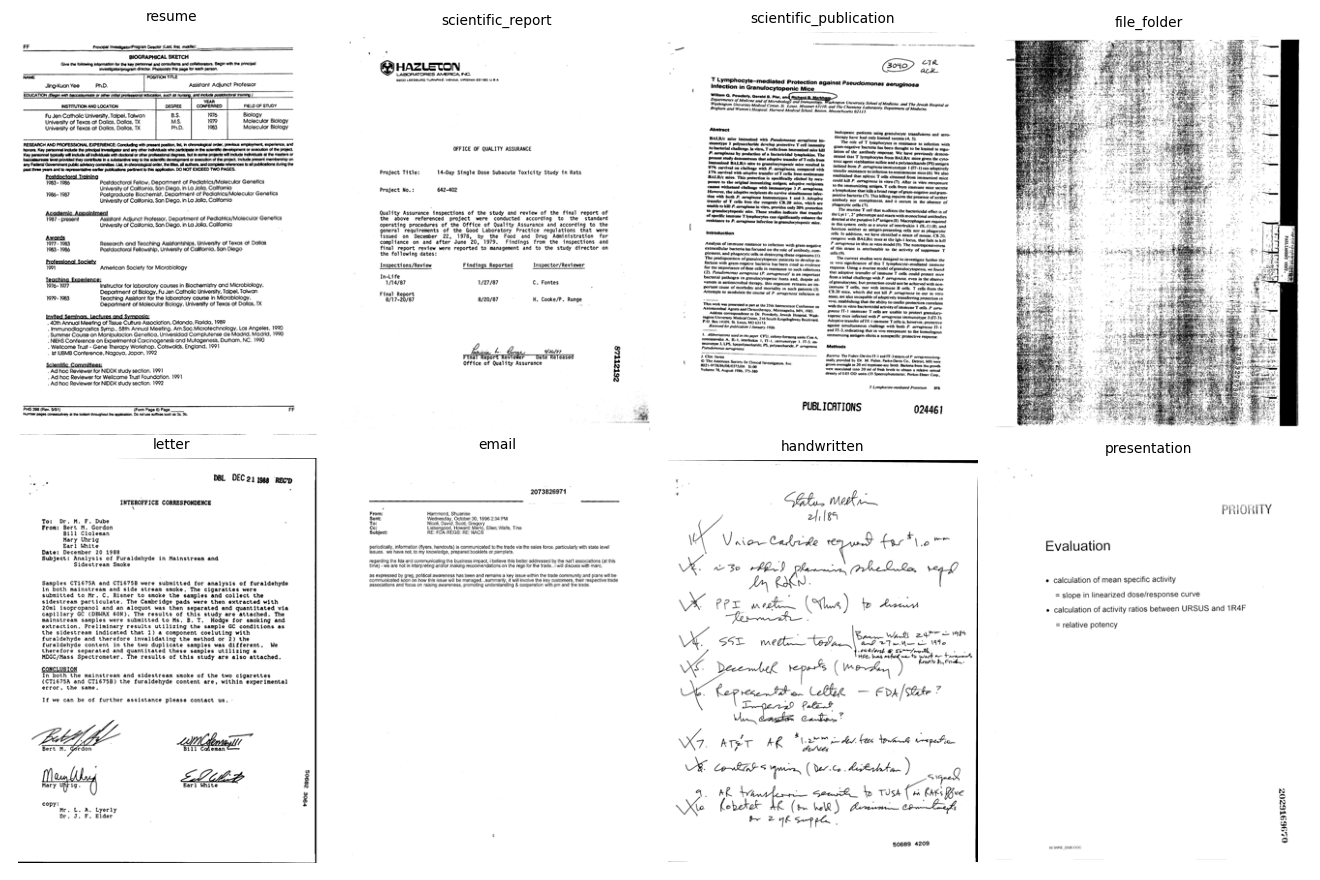

In [16]:
# Preview: hanya beberapa gambar, untuk memastikan path, orientasi, dan kelas masuk akal.
import matplotlib.pyplot as plt
from docvision_v2.data import open_document

preview = train_frame.groupby('label', sort=True).head(1).head(8)
fig, axes = plt.subplots(2, 4, figsize=(12, 8))
for axis in axes.flat:
    axis.axis('off')
for axis, row in zip(axes.flat, preview.itertuples(index=False)):
    image, _ = open_document(row.resolved_path, row.zip_member)
    image.thumbnail((320, 420))
    axis.imshow(image)
    axis.set_title(manifest['class_names'][int(row.label)], fontsize=9)
fig.tight_layout()
fig.savefig(PROJECT / 'reports/class_preview.png', dpi=110)
plt.close(fig)
display(DisplayImage(filename=str(PROJECT / 'reports/class_preview.png')))

### 4. Training dan resume

Default: maksimum 20 epoch/model; 320 piksel pada epoch 1–14 dan 384 pada epoch 15–20.
Validasi setiap epoch selalu pada 384 piksel agar checkpoint dapat dibandingkan.
AdamW, warmup/cosine, LR classifier 5× backbone, gradient accumulation, AMP, dan EMA disertakan.
Mixup ringan hanya pada fase awal dan tidak dipakai pada fine-tuning akhir.

`best.pt` menyimpan EMA terbaik berdasarkan accuracy, dengan cross-entropy sebagai tie-break.
`last.pt` menyimpan keadaan lengkap untuk resume. Model yang sudah selesai dilewati setelah
config dan fingerprint diperiksa. Jika ingin mengubah hyperparameter, gunakan `RUN_TAG` baru.

Jika CUDA out-of-memory, gunakan run baru dengan batch 4 dan accumulation 8; effective batch
tetap 32, tetapi statistik BatchNorm EfficientNet tetap bergantung pada batch fisik.

In [17]:
from pathlib import Path
import gc
import importlib
import inspect
import sys
import torch

PROJECT = Path(PROJECT)
engine_file = PROJECT / "src/docvision_v2/engine.py"
source = engine_file.read_text()

if "including_emulation" not in inspect.signature(
    torch.cuda.is_bf16_supported
).parameters:
    raise RuntimeError(
        "API PyTorch berbeda. Kirim output print(torch.__version__)."
    )

# Perbaiki kedua pemeriksaan BF16: autocast DAN GradScaler.
updated = source.replace(
    "torch.cuda.is_bf16_supported()",
    "torch.cuda.is_bf16_supported(including_emulation=False)"
).replace(
    "torch.backends.cudnn.benchmark = True",
    "torch.backends.cudnn.benchmark = False"
).replace(
    "torch.channels_last",
    "torch.contiguous_format"
)

if "including_emulation=False" not in updated:
    raise RuntimeError("Isi engine.py berbeda dari versi yang diperiksa.")

compile(updated, str(engine_file), "exec")

# Simpan source sebelumnya sebelum menerapkan patch.
if updated != source:
    backup = engine_file.with_suffix(".py.before_gpu_fix")
    if not backup.exists():
        backup.write_text(source)
    temporary = engine_file.with_suffix(".py.tmp")
    temporary.write_text(updated)
    temporary.replace(engine_file)

# Muat ulang fungsi yang sudah telanjur diimpor notebook.
sys.path.insert(0, str(PROJECT / "src"))
importlib.invalidate_caches()

import docvision_v2.engine as engine_module
import docvision_v2.evaluate as evaluate_module

importlib.reload(engine_module)
importlib.reload(evaluate_module)

train_model = engine_module.train_model
evaluate_model = evaluate_module.evaluate_model
compare_models = evaluate_module.compare_models
export_review = evaluate_module.export_review

# Pisahkan percobaan perbaikan dari folder run sebelumnya.
RUN_TAG = str(RUN_TAG)
if "_gpu_fix" not in RUN_TAG:
    RUN_TAG += "_gpu_fix"

base_tag, attempt = RUN_TAG, 2
while any(
    (folder := PROJECT / "outputs" /
     f'{name}_{RUN_TAG}_seed{CONFIGS[name]["seed"]}').is_dir()
    and any(folder.iterdir())
    and not (folder / "last.pt").is_file()
    for name in MODELS
):
    RUN_TAG = f"{base_tag}_{attempt}"
    attempt += 1

# Lepaskan referensi exception sebelumnya bila masih tersimpan.
for attribute in ("last_traceback", "last_value", "last_exc"):
    if hasattr(sys, attribute):
        setattr(sys, attribute, None)

gc.collect()
torch.backends.cudnn.benchmark = False

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version())

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    native_bf16 = torch.cuda.is_bf16_supported(
        including_emulation=False
    )
    free, total = torch.cuda.mem_get_info()

    print("GPU:", torch.cuda.get_device_name())
    print("Compute capability:", torch.cuda.get_device_capability())
    print("BF16 native:", native_bf16)
    print("AMP:", "BF16" if native_bf16 else "FP16 + GradScaler")
    print(f"VRAM tersedia: {free / 2**30:.2f}/{total / 2**30:.2f} GiB")

print("RUN_TAG:", RUN_TAG)
print("Patch selesai. Jalankan kembali sel RUN_DIRS/training.")

PyTorch: 2.11.0+cu128
CUDA build: 12.8
cuDNN: 91900
GPU: Tesla T4
Compute capability: (7, 5)
BF16 native: False
AMP: FP16 + GradScaler
VRAM tersedia: 14.46/14.56 GiB
RUN_TAG: v2_gpu_fix
Patch selesai. Jalankan kembali sel RUN_DIRS/training.


In [18]:
RUN_DIRS = []
for name in MODELS:
    run_name = f'{name}_{RUN_TAG}_seed{CONFIGS[name]["seed"]}'
    run_dir = PROJECT / 'outputs' / run_name
    if ENABLE_TRAINING:
        run_dir = train_model(PROJECT, CONFIGS[name], run_name=run_name,
                              max_hours=MAX_HOURS_PER_MODEL)
    elif not (run_dir / 'best.pt').is_file():
        raise FileNotFoundError(f'Checkpoint belum tersedia: {run_dir / "best.pt"}')
    RUN_DIRS.append(run_dir)
    display(pd.read_csv(run_dir / 'history.csv').tail())
    print(json.dumps(json.loads((run_dir / 'summary.json').read_text()), indent=2))

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 144MB/s] 


convnext_tiny | train=25,567, valid=6,392 | cuda | start epoch=1
epoch 1 | batch 100/3196 | loss 2.8255
epoch 1 | batch 200/3196 | loss 2.8158
epoch 1 | batch 300/3196 | loss 2.8019
epoch 1 | batch 400/3196 | loss 2.7813
epoch 1 | batch 500/3196 | loss 2.7485
epoch 1 | batch 600/3196 | loss 2.7032
epoch 1 | batch 700/3196 | loss 2.6455
epoch 1 | batch 800/3196 | loss 2.5798
epoch 1 | batch 900/3196 | loss 2.5140
epoch 1 | batch 1000/3196 | loss 2.4538
epoch 1 | batch 1100/3196 | loss 2.3961
epoch 1 | batch 1200/3196 | loss 2.3457
epoch 1 | batch 1300/3196 | loss 2.2975
epoch 1 | batch 1400/3196 | loss 2.2521
epoch 1 | batch 1500/3196 | loss 2.2077
epoch 1 | batch 1600/3196 | loss 2.1661
epoch 1 | batch 1700/3196 | loss 2.1279
epoch 1 | batch 1800/3196 | loss 2.0963
epoch 1 | batch 1900/3196 | loss 2.0665
epoch 1 | batch 2000/3196 | loss 2.0340
epoch 1 | batch 2100/3196 | loss 2.0043
epoch 1 | batch 2200/3196 | loss 1.9764
epoch 1 | batch 2300/3196 | loss 1.9520
epoch 1 | batch 2400/319

,epoch,image_size,train_loss,train_soft_accuracy,val_accuracy,val_macro_f1,val_log_loss,lr,seconds
15,16,384,0.161025,0.995971,0.873748,0.873647,0.555733,0.000014,424.318081
16,17,384,0.156890,0.997301,0.874218,0.873996,0.561161,0.000009,425.507462
17,18,384,0.154784,0.997731,0.874374,0.874207,0.566750,0.000005,424.384048
18,19,384,0.155278,0.997575,0.873436,0.873224,0.568541,0.000003,424.999044
19,20,384,0.153784,0.997849,0.873436,0.873328,0.569529,0.000002,424.333063


{
  "model": "convnext_tiny",
  "completed_epoch": 20,
  "planned_epochs": 20,
  "best_validation_accuracy": 0.8743742177722152,
  "best_validation_log_loss": 0.5667495460092473,
  "finished": true,
  "early_stopped": false,
  "score_type": "model-selection holdout; not independent final test / Kaggle score",
  "public_score": null,
  "private_score": null
}
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 187MB/s]


efficientnet_v2_s | train=25,567, valid=6,392 | cuda | start epoch=1
epoch 1 | batch 100/3196 | loss 2.7944
epoch 1 | batch 200/3196 | loss 2.7884
epoch 1 | batch 300/3196 | loss 2.7829
epoch 1 | batch 400/3196 | loss 2.7752
epoch 1 | batch 500/3196 | loss 2.7635
epoch 1 | batch 600/3196 | loss 2.7461
epoch 1 | batch 700/3196 | loss 2.7242
epoch 1 | batch 800/3196 | loss 2.6963
epoch 1 | batch 900/3196 | loss 2.6554
epoch 1 | batch 1000/3196 | loss 2.6108
epoch 1 | batch 1100/3196 | loss 2.5548
epoch 1 | batch 1200/3196 | loss 2.5015
epoch 1 | batch 1300/3196 | loss 2.4497
epoch 1 | batch 1400/3196 | loss 2.4026
epoch 1 | batch 1500/3196 | loss 2.3537
epoch 1 | batch 1600/3196 | loss 2.3117
epoch 1 | batch 1700/3196 | loss 2.2702
epoch 1 | batch 1800/3196 | loss 2.2343
epoch 1 | batch 1900/3196 | loss 2.1977
epoch 1 | batch 2000/3196 | loss 2.1633
epoch 1 | batch 2100/3196 | loss 2.1307
epoch 1 | batch 2200/3196 | loss 2.1014
epoch 1 | batch 2300/3196 | loss 2.0722
epoch 1 | batch 2400

,epoch,image_size,train_loss,train_soft_accuracy,val_accuracy,val_macro_f1,val_log_loss,lr,seconds
15,16,384,0.170606,0.992647,0.873123,0.872812,0.597911,0.000027,527.004055
16,17,384,0.162583,0.995267,0.871715,0.871475,0.614114,0.000017,527.457164
17,18,384,0.157203,0.996832,0.869681,0.869620,0.625319,0.000010,524.740777
18,19,384,0.155849,0.997067,0.868742,0.868605,0.633289,0.000006,522.082879
19,20,384,0.155834,0.997067,0.870776,0.870637,0.636940,0.000004,525.010893


{
  "model": "efficientnet_v2_s",
  "completed_epoch": 20,
  "planned_epochs": 20,
  "best_validation_accuracy": 0.8731226533166458,
  "best_validation_log_loss": 0.5979109662471934,
  "finished": true,
  "early_stopped": false,
  "score_type": "model-selection holdout; not independent final test / Kaggle score",
  "public_score": null,
  "private_score": null
}


### 5. Evaluasi akhir, TTA, dan submission masing-masing model

Bandingkan satu resolusi dengan rata-rata prediksi 384+448, tanpa flip teks.
TTA hanya dipilih bila validation accuracy meningkat, atau accuracy sama dan CE lebih rendah.
Peningkatan dari pemilihan tersebut merupakan **skor seleksi pada holdout**, bukan evaluasi test independen.

Laporan mencakup confusion matrix, metrik per kelas, kesalahan ber-confidence tinggi,
serta clean-training-sample accuracy untuk membantu menilai overfitting.

In [19]:
from pathlib import Path

WORKING = Path("/kaggle/working")

checkpoints = sorted(WORKING.rglob("best.pt"))

print("=== HASIL PEMERIKSAAN CHECKPOINT ===")
print("Jumlah checkpoint:", len(checkpoints))

for i, checkpoint in enumerate(checkpoints, 1):
    print(f"\nModel {i}")
    print("Checkpoint:", checkpoint)
    print("Ukuran (MB):", round(
        checkpoint.stat().st_size / (1024**2), 2
    ))
    print("History tersedia:",
          (checkpoint.parent / "history.csv").exists())
    print("Summary tersedia:",
          (checkpoint.parent / "summary.json").exists())

=== HASIL PEMERIKSAAN CHECKPOINT ===
Jumlah checkpoint: 2

Model 1
Checkpoint: /kaggle/working/docvision_v2/outputs/convnext_tiny_v2_gpu_fix_seed42/best.pt
Ukuran (MB): 106.22
History tersedia: True
Summary tersedia: True

Model 2
Checkpoint: /kaggle/working/docvision_v2/outputs/efficientnet_v2_s_v2_gpu_fix_seed42/best.pt
Ukuran (MB): 77.83
History tersedia: True
Summary tersedia: True


Validasi convnext_tiny pada 384px
Validasi convnext_tiny pada 448px
Prediksi test convnext_tiny pada 384px
convnext_tiny_v2_gpu_fix_seed42
{
  "accuracy": 0.8743742177722152,
  "macro_f1": 0.8742072464678626,
  "log_loss": 0.5667495460092473,
  "unique_image_group_accuracy": 0.874491392801252,
  "correct": 5589,
  "rows": 6392
}


,Unnamed: 0,precision,recall,f1-score,support
0,advertisement,0.886420,0.904282,0.895262,397.0
1,budget,0.846547,0.825436,0.835859,401.0
2,email,0.975248,0.977667,0.976456,403.0
3,file_folder,0.921569,0.930693,0.926108,404.0
4,form,0.722096,0.790524,0.754762,401.0
5,handwritten,0.904206,0.955556,0.929172,405.0
6,invoice,0.861809,0.866162,0.863980,396.0
7,letter,0.872180,0.883249,0.877680,394.0
8,memo,0.943152,0.914787,0.928753,399.0
9,news_article,0.918256,0.855330,0.885677,394.0


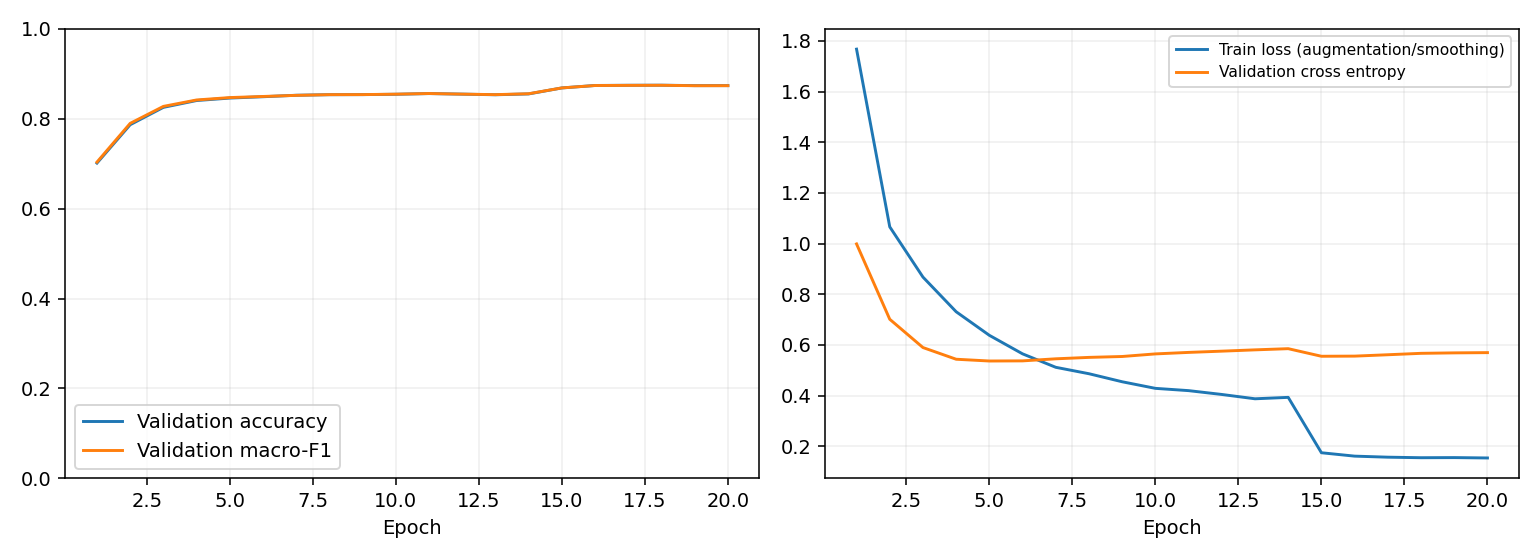

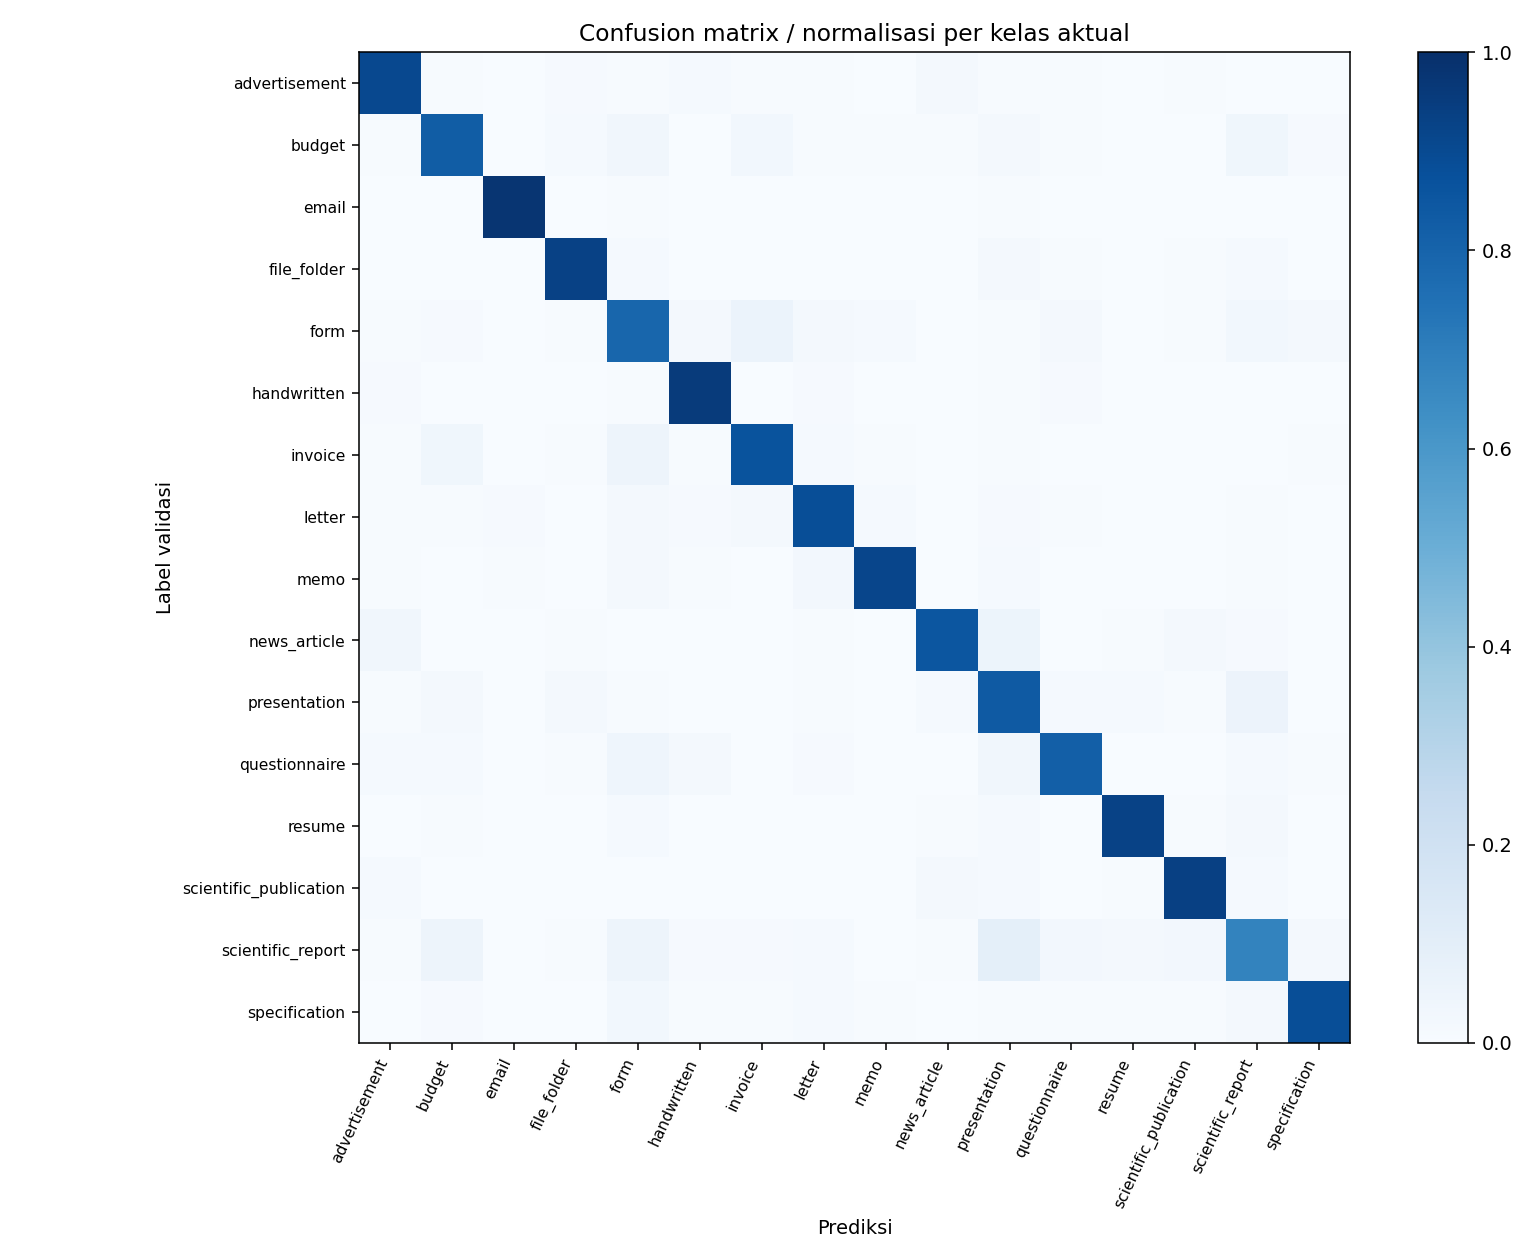

Validasi efficientnet_v2_s pada 384px
Validasi efficientnet_v2_s pada 448px
Prediksi test efficientnet_v2_s pada 384px
efficientnet_v2_s_v2_gpu_fix_seed42
{
  "accuracy": 0.8731226533166458,
  "macro_f1": 0.8728123992049469,
  "log_loss": 0.5979109662471934,
  "unique_image_group_accuracy": 0.8730829420970266,
  "correct": 5581,
  "rows": 6392
}


,Unnamed: 0,precision,recall,f1-score,support
0,advertisement,0.897436,0.881612,0.889454,397.0
1,budget,0.825472,0.872818,0.848485,401.0
2,email,0.985000,0.977667,0.981320,403.0
3,file_folder,0.916462,0.923267,0.919852,404.0
4,form,0.756281,0.750623,0.753442,401.0
5,handwritten,0.919431,0.958025,0.938331,405.0
6,invoice,0.867188,0.840909,0.853846,396.0
7,letter,0.873449,0.893401,0.883312,394.0
8,memo,0.927318,0.927318,0.927318,399.0
9,news_article,0.900000,0.845178,0.871728,394.0


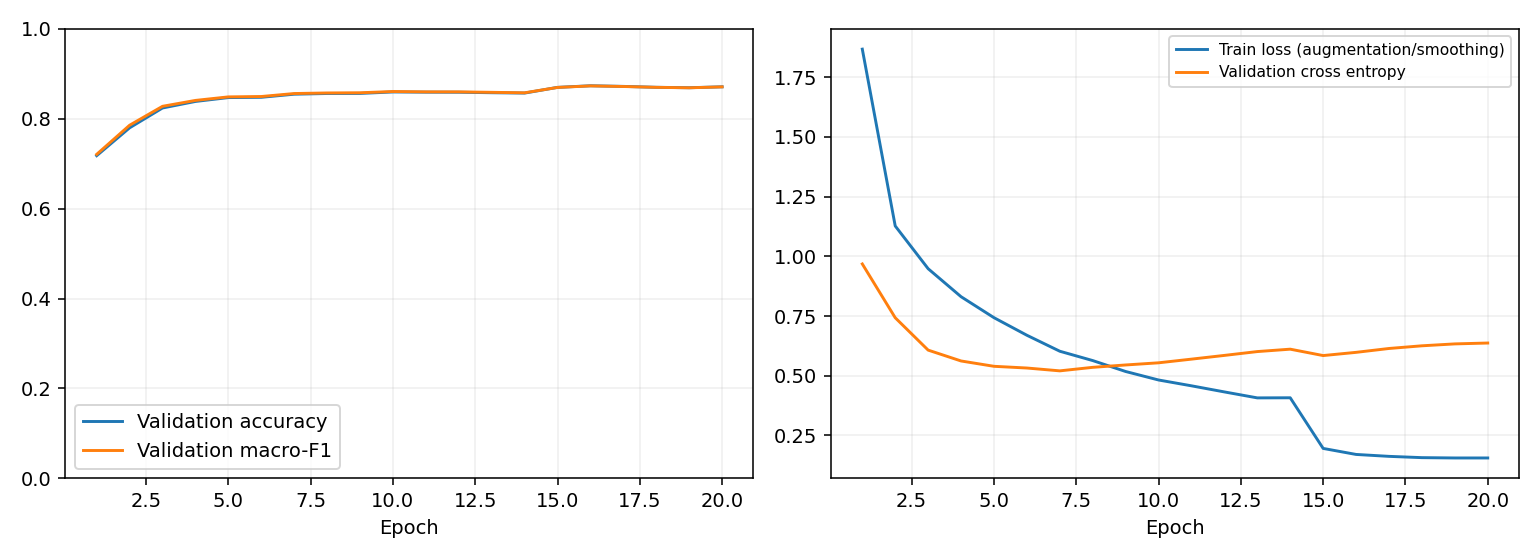

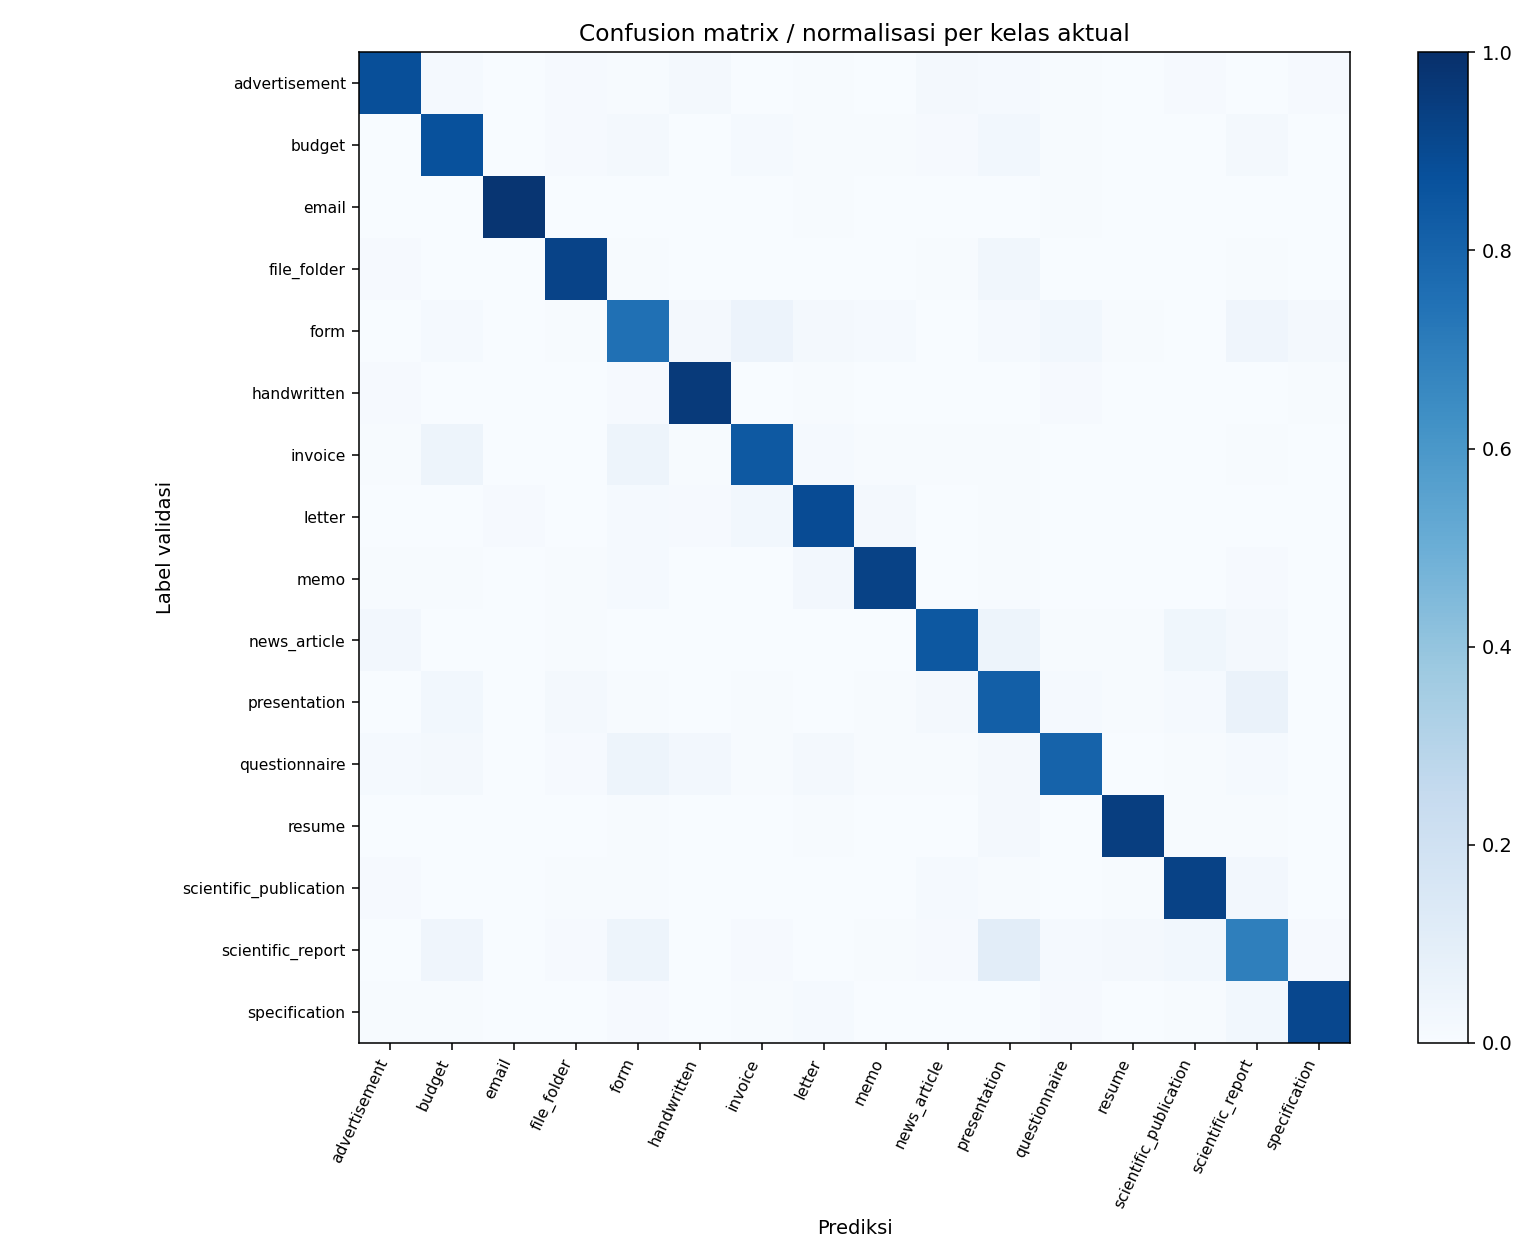

In [20]:
EVALUATION_DIRS = []
for run_dir in RUN_DIRS:
    evaluation = evaluate_model(PROJECT, run_dir)
    EVALUATION_DIRS.append(evaluation)
    print(run_dir.name)
    print(json.dumps(json.loads((evaluation / 'metrics.json').read_text()), indent=2))
    display(pd.read_csv(evaluation / 'classification_report.csv').head(EXPECTED_CLASSES))
    display(DisplayImage(filename=str(evaluation / 'training_curves.png')))
    display(DisplayImage(filename=str(evaluation / 'confusion_matrix.png')))

### 6. Bandingkan model tunggal dan ensemble 50:50

Tidak ada pencarian ratusan bobot ensemble pada validasi. Dua model tunggal dan satu
ensemble dengan bobot tetap dibandingkan; validation accuracy tertinggi dipilih,
dan log-loss menjadi tie-break. Jika hanya satu model dijalankan, model itu dipakai.
Prediksi selalu diselaraskan ke urutan ID `sample_submission.csv`.

In [21]:
comparison = compare_models(PROJECT, EVALUATION_DIRS)
display(comparison)
final_submission = pd.read_csv(PROJECT / 'submission.csv', dtype={'id': str})
assert list(final_submission.columns) == list(sample_submission.columns)
assert list(final_submission.id) == list(sample_submission.id)
assert final_submission.shape == sample_submission.shape
assert final_submission.label.between(0, EXPECTED_CLASSES-1).all()
assert not final_submission.isna().any().any()
display(final_submission.head())
print('Submission valid:', final_submission.shape)

            model  accuracy  macro_f1  log_loss
   ensemble_equal  0.884230  0.884022  0.487083
    convnext_tiny  0.874374  0.874207  0.566750
efficientnet_v2_s  0.873123  0.872812  0.597911
Terpilih: ensemble_equal -> /kaggle/working/docvision_v2/submission.csv


,model,accuracy,macro_f1,log_loss
2,ensemble_equal,0.884230,0.884022,0.487083
0,convnext_tiny,0.874374,0.874207,0.566750
1,efficientnet_v2_s,0.873123,0.872812,0.597911


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,1
3,test_00004,4
4,test_00005,13


Submission valid: (7994, 2)


### 7. File output dan paket review

`submission.csv` adalah pilihan berdasarkan validasi. CSV setiap model juga tersedia.
`docvision_v2_review.zip` berisi log, metrik, probabilitas, audit, dan diagnostik;
tidak memasukkan dataset atau checkpoint besar. Simpan versi notebook agar checkpoint
tetap tersedia. Jangan menganggap skor validasi sebagai skor public/private Kaggle.

In [22]:
review_zip = export_review(PROJECT)
artifact_root = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else PROJECT
artifacts = [PROJECT / 'submission.csv', PROJECT / 'submission_manifest.json', review_zip]
artifacts += sorted((PROJECT / 'outputs/comparison').glob('submission_*.csv'))
for source in artifacts:
    target = artifact_root / source.name
    if source.resolve() != target.resolve():
        shutil.copy2(source, target)
    print(target)
    display(FileLink(str(target)))
print('Jika link tidak terbuka, unduh melalui panel Output/Files Kaggle.')

/kaggle/working/submission.csv


/kaggle/working/submission.csv

/kaggle/working/submission_manifest.json


/kaggle/working/submission_manifest.json

/kaggle/working/docvision_v2_review.zip


...

/kaggle/working/submission_efficientnet_v2_s.csv


/kaggle/working/submission_efficientnet_v2_s.csv

/kaggle/working/submission_ensemble_equal.csv


/kaggle/working/submission_ensemble_equal.csv

Jika link tidak terbuka, unduh melalui panel Output/Files Kaggle.


### 8. Pengujian opsional

Pengujian sintetis memeriksa akses TIFF/ZIP, cache, duplikat, resume, ID submission,
gradient accumulation, serta forward/backward backbone asli. Hasilnya bukan skor kompetisi.
Jalankan hanya bila diperlukan; pengujian dipaksa ke CPU dalam proses terpisah.

In [23]:
if RUN_SMOKE_TESTS:
    import subprocess
    env = os.environ.copy()
    env['CUDA_VISIBLE_DEVICES'] = ''
    subprocess.run([sys.executable, str(PROJECT / 'tests/smoke_test.py'),
                    str(PROJECT / 'LOCAL_SMOKE_REPORT.json')], env=env, check=True)
else:
    print('Smoke test opsional dilewati. Hasil pengujian pengembangan: VALIDATION_REPORT.json')

Smoke test opsional dilewati. Hasil pengujian pengembangan: VALIDATION_REPORT.json


### 9. Audit notebook lama dan analisis rancangan

| Temuan pada file ResNet18 | Dampak | Penanganan v2 |
|---|---|---|
| Laporan audit dibaca sebelum dibuat | Run All berhenti dengan FileNotFoundError | Urutan prepare → audit → split → train |
| Folder dataset dikunci ke path tertentu | Dataset yang terpasang berbeda tidak terdeteksi | Autodeteksi CSV gambar dan override eksplisit |
| Pembuatan dataset bersih, audit, dan split berulang | Waktu persiapan dan inkonsistensi metadata | File gambar tetap di tempat; cache audit per file |
| Script `buat_dua_submission_kaggle.py` dicari tetapi tidak disertakan | EfficientNet/ConvNeXt tidak dapat dijalankan mandiri | Seluruh source tersedia di notebook |
| Factory lama tidak menyediakan EfficientNetV2-S | Sel lanjutan bergantung pada patch luar | Kedua arsitektur tersedia dan diuji forward/backward |
| Tidak ada output training yang membuktikan skor pada file yang dikirim | Tidak ada baseline empiris untuk klaim peningkatan | History dan metrik hanya ditulis dari run nyata |

Resep v2 ditujukan untuk eksperimen yang lebih kuat, tetapi tidak membuktikan bahwa
ConvNeXt, EfficientNet, EMA, mixup, atau ensemble pasti meningkatkan skor pada dataset ini.
Pengaruhnya harus dilihat melalui split tetap dan hasil yang benar-benar dijalankan.

**Risiko interpretasi:** (1) exact-hash tidak mengatasi semua near-duplicate;
(2) pemilihan epoch/TTA/model pada validasi yang sama menambah selection bias;
(3) hasil tinggi pada satu seed belum berarti stabil; (4) checkpoint ImageNet-only
mengurangi risiko pretrained pada dataset target tetapi bukan bukti nol kontaminasi
untuk setiap gambar publik; (5) benchmark ResNet18 hanya adil bila splitnya sama.

**Urutan tindak lanjut setelah run:** periksa kurva dan confusion matrix → identifikasi
underfitting/overfitting dengan clean-train sample → pilih satu perubahan yang beralasan →
gunakan run baru pada split tetap → simpan semua hasil, termasuk yang tidak meningkat.
Untuk klaim generalisasi final, sediakan data evaluasi yang belum dipakai menyeleksi model.

### Lampiran — analisis dan panduan lengkap

# Document Image Classification — v2

EfficientNetV2-S dan ConvNeXt Tiny, menggunakan PyTorch/torchvision. Notebook
utama bersifat mandiri: seluruh source proyek ditulis oleh notebook, sehingga
tidak memerlukan `buat_dua_submission_kaggle.py` atau upload gambar satu per satu.

## Status bukti

- Notebook sumber diaudit: ada output `FileNotFoundError` untuk laporan audit
  dan konflik yang belum tersedia. Tidak ditemukan output training yang
  membuktikan akurasi validasi ResNet18 pada file tersebut.
- Implementasi v2 diuji menggunakan TIFF sintetis pada CPU. Notebook lengkap
  juga dijalankan dari awal sampai submission menggunakan kedua arsitektur
  sebenarnya (masing-masing satu epoch, bobot acak, tiga kelas sintetis).
  Pengujian mencakup training, evaluasi, ensemble, dan ekspor paket review.
  Lihat `VALIDATION_REPORT.json` dan `NOTEBOOK_EXECUTION_REPORT.json`.
- Lingkungan uji lokal: Python 3.12, torch 2.8.0+cpu, torchvision 0.23.0+cpu.
  Jalur CUDA/AMP, bobot pretrained, dan skala dataset penuh belum diuji lokal.
- Belum dilatih pada 32 ribu gambar kompetisi dan belum dijalankan pada GPU
  Kaggle. **Tidak ada angka akurasi kompetisi yang dibuat atau dijanjikan.**
- Istilah "v2" menandai revisi notebook. EfficientNetV2-S merupakan nama
  arsitektur kedua, selain ConvNeXt Tiny. Kedua arsitektur dilatih terpisah.

## Cara memakai di Kaggle

1. Import notebook `.ipynb`, aktifkan GPU, dan pastikan dataset gambar sudah
   ditambahkan melalui Add Input. Jika gambar tersedia di sesi yang sama,
   `/kaggle/working/document_image_classification_clean` diprioritaskan.
2. Jalankan sel pengaturan. Biarkan `DATA_ROOT=None` untuk autodeteksi, atau isi
   folder yang berisi `train.csv`, `test.csv`, dan `sample_submission.csv`.
   `IMAGE_ROOTS` dapat ditambah jika gambar terletak di folder lain.
3. Jalankan sel secara berurutan. Notebook tidak mengganti instalasi PyTorch
   Kaggle. Internet dibutuhkan untuk download awal bobot ImageNet resmi;
   jika offline, berikan file `.pth` torchvision melalui konfigurasi model.
4. Audit membaca gambar sekali dan menyimpan hasil per file di SQLite. Rerun
   menggunakan cache untuk file dengan path, ukuran, dan mtime yang sama.
   Audit tidak membuat folder salinan, symlink, atau file gambar baru.
5. Latih ConvNeXt Tiny dan EfficientNetV2-S pada split yang sama. Untuk membatasi
   durasi satu eksekusi, isi `MAX_HOURS_PER_MODEL`; batas tersebut diperiksa
   setelah epoch selesai. Ulangi sel training untuk meneruskan checkpoint.
6. Sel evaluasi menulis submission masing-masing model, ensemble 50:50, dan
   `submission.csv` yang dipilih berdasarkan validation accuracy.
7. Gunakan Save Version untuk mempertahankan output. Jangan mengandalkan
   folder `/kaggle/working` dari sesi yang sudah berakhir. Dataset dari sesi
   lama perlu dipasang sebagai dataset/input atau output notebook tersimpan.

## Data langsung dan format yang didukung

CSV sumber tidak dimodifikasi. Kolom path dapat bernama `filename` atau
`image_path` (juga `path`, `filepath`, `file_path`). Label kompetisi ini harus
integer 0 sampai 15. Submission mengikuti template `id,label` dan disejajarkan
berdasarkan ID, termasuk ID yang memiliki nol di depan.

Jika gambar belum diekstrak dan hanya tersedia di ZIP, anggota ZIP dibaca
langsung tanpa ekstraksi. Ini menghemat ruang penyimpanan tetapi dapat
memperlambat pembacaan TIFF pada setiap epoch. Jika file gambar sudah ada,
file tersebut diprioritaskan. Tidak ada konversi massal atau salinan otomatis.
Pembacaan dan decoding minibatch tetap diperlukan oleh model.

## Audit dan pembagian validasi

- Gambar training tidak terbaca dilaporkan dan dikeluarkan lewat metadata.
  Lebih dari 1% kegagalan (minimal ambang dua file) menghentikan proses agar
  salah path tidak menyebabkan penghapusan ribuan baris secara diam-diam.
- Gambar test gagal dibaca selalu menghentikan proses. Tidak ada prediksi
  menggunakan gambar kosong atau penghapusan baris submission.
- Semua baris kelompok piksel identik dengan label berbeda dikarantina.
  Label tidak diubah menggunakan voting atau asumsi nama folder.
- Duplikat berlabel sama ditempatkan dalam sisi split yang sama. Selain
  akurasi per baris, laporan menyertakan akurasi per gambar unik.
- Train/test exact overlap dilaporkan. Tidak ada penyalinan label ke test,
  lookup ID, atau penggunaan nama folder/filename sebagai fitur model.
- Split lama dapat dipakai kembali hanya jika ID, path, label, cakupan data,
  dan pemisahan kelompok duplikat lolos verifikasi. Jika tidak, notebook
  membuat holdout baru sekitar 80:20 dan mencatat asal split.
- Hash persis tidak mendeteksi near-duplicate atau halaman terkait dari satu
  dokumen. Bila identitas sumber dokumen tersedia, perlu split berdasarkan
  identitas tersebut sebelum menginterpretasikan hasil sebagai generalisasi
  ke sumber dokumen yang benar-benar baru.

## Resep training dan alasannya

| Komponen | Default | Tujuan dan batasan |
|---|---|---|
| Bobot awal | ImageNet-1K torchvision | Transfer fitur visual umum; tidak memakai checkpoint RVL-CDIP yang bisa tumpang tindih dengan dataset |
| Backbone | ConvNeXt Tiny; EfficientNetV2-S | Dua arsitektur untuk dibandingkan dan diuji ensemble, bukan jaminan satu selalu unggul |
| Resolusi | 320, lalu 384 mulai epoch 15 | Memberi kesempatan model belajar detail halaman setelah adaptasi awal |
| Epoch | Maksimum 20 per model | Titik awal eksperimen; checkpoint dipilih dari validasi |
| Batch | 8 × akumulasi 4 = efektif 32 | Membatasi kebutuhan VRAM; akumulasi tidak membuat statistik BatchNorm setara dengan batch fisik 32 |
| Learning rate | ConvNeXt 1e-4; EfficientNet 2e-4 | LR backbone konservatif, classifier 5× lebih besar |
| Scheduler | Warmup 2 epoch, cosine decay | Mengurangi perubahan mendadak pada awal fine-tuning |
| Optimizer | AdamW, decay 0,01 | Bias dan parameter norm tidak dikenai weight decay |
| Augmentasi | Affine ringan, brightness/contrast ringan | Menjaga sebagian besar layout; tidak ada horizontal flip atau random crop besar |
| Label smoothing | 0,05, lalu 0,02 | Regularisasi ringan; tetap perlu diuji terhadap validasi |
| Mixup | alpha 0,1; peluang 0,25 pada fase awal | Dapat membantu regularisasi; dimatikan saat fine-tuning resolusi tinggi; manfaatnya bukan kepastian |
| EMA | decay maksimal 0,999 dengan warmup | Validasi dan best checkpoint memakai EMA; last checkpoint juga menyimpan bobot mentah untuk resume |
| AMP | BF16 bila didukung, selain itu FP16 + scaler | Efisiensi GPU; CPU tests memakai FP32 |
| TTA | Bandingkan 384 saja versus rata-rata 384+448 | Dipakai hanya jika membantu validation accuracy, dengan CE sebagai tie-break |
| Ensemble | Rata-rata probabilitas 50:50 | Dibandingkan dengan dua model tunggal; ensemble yang lebih buruk tidak dipilih |

Resolusi lebih tinggi dan TTA menambah waktu. Training menggunakan satu GPU
yang terlihat sebagai `cuda:0`; GPU kedua tidak otomatis mempercepat training.
Tidak ada klaim waktu selesai karena GPU, I/O, dan kompresi TIFF memengaruhinya.

## Mengukur kualitas secara jujur

`best_validation_accuracy` adalah skor holdout untuk memilih epoch/model,
bukan skor public/private Kaggle. Pemilihan epoch, TTA, dan model pada holdout
yang sama dapat membuat angka terpilih optimistis. Jangan mencoba banyak seed
split lalu hanya melaporkan yang tertinggi.

Periksa secara bersama-sama:

1. Kurva validation accuracy, macro-F1 dan loss.
2. Akurasi clean training sample dengan preprocessing evaluasi. Train accuracy
   selama mixup bukan pembanding langsung karena target dan augmentasinya berbeda.
3. Recall per kelas dan confusion matrix, terutama kelas yang bentuknya mirip.
4. Kesalahan dengan confidence tinggi: gunakan untuk review label/layout,
   bukan otomatis mengganti label agar skor validasi naik.
5. Jumlah contoh yang benar-benar berubah ketika TTA/ensemble memperbaiki skor.
   Perbedaan yang hanya beberapa contoh belum membuktikan generalisasi lebih baik.
6. Untuk laporan final yang lebih kuat, gunakan holdout lain yang tidak dipakai
   memilih konfigurasi atau cross-validation berbasis kelompok dengan budget memadai.

Tidak ada inverse-frequency loss atau oversampling secara default karena
target utama adalah accuracy. Jika minoritas memiliki recall buruk, uji satu
perubahan pada split yang tetap dan bandingkan accuracy serta macro-F1.

## Strategi peningkatan sesudah run nyata

- Jika training dan validasi masih meningkat sampai akhir, tambah horizon di
  **run baru**. Jangan mengubah horizon scheduler pada resume eksperimen lama.
- Jika clean-train tinggi dan validasi stagnan/turun, coba kurangi epoch atau
  LR, dan bandingkan regularisasi satu per satu.
- Jika training juga rendah, periksa mapping label, preview gambar, bobot
  pretrained, LR, dan augmentasi sebelum memperbesar model.
- Jika fitur teks kecil sering gagal, bandingkan fine-tuning 448 pada satu run
  terkontrol dengan batch lebih kecil. Resolusi tinggi bukan obat untuk label salah.
- Jika satu arsitektur jelas lebih baik dan GPU terbatas, prioritaskan model
  tersebut. Ensemble hanya berguna bila kesalahannya saling melengkapi.
- Refit seluruh train belum otomatis dilakukan dalam v2: submission default
  berasal dari model yang mempunyai bukti validasi. Setelah konfigurasi dan
  horizon terkunci, refit dapat menjadi eksperimen terpisah tanpa klaim memiliki
  validation score independen.

## Checkpoint dan reproduksi

- `best.pt`: bobot EMA terpilih, config, epoch, kelas, metrik, fingerprint data,
  dan hash source; digunakan untuk inferensi tanpa download pretrained ulang.
- `last.pt`: bobot mentah dan EMA, optimizer, scaler, RNG, langkah LR, history,
  serta status selesai; digunakan untuk melanjutkan epoch berikutnya.
- Resume menolak config, data/split, atau source yang berubah. Gunakan `RUN_TAG`
  baru untuk eksperimen baru. Memakai checkpoint model lain akan ditolak.
- Semua file training, termasuk checkpoint, tetap di output Kaggle; paket
  review tidak memasukkan checkpoint besar atau dataset.
- Fingerprint split mencakup ID, label, hash piksel, ID validasi, dan urutan
  template. Prediksi kedua model harus memiliki fingerprint dan urutan sama
  sebelum ensemble boleh dibuat.
- Cache audit menggunakan ukuran/mtime file atau CRC ZIP; cache diasumsikan
  untuk dataset yang tidak dimodifikasi secara tersembunyi. Hapus cache bila
  file sengaja diubah sambil mempertahankan seluruh metadata tersebut.
- Seed disimpan, tetapi CUDA tidak dijanjikan identik bit demi bit antarmesin.

## Struktur proyek setelah notebook dijalankan

```text
docvision_v2/
  src/docvision_v2/    # data, model, training, evaluasi, utilities
  scripts/run.py      # CLI alternatif
  tests/smoke_test.py # pengujian TIFF sintetis
  configs/           # konfigurasi nyata tiap model
  data/splits/       # metadata split dan manifest
  data/audit_cache.sqlite3
  reports/           # audit data dan distribusi kelas
  outputs/           # checkpoint, history, evaluasi, perbandingan
  submission.csv
  submission_manifest.json
  docvision_v2_review.zip
```

Contoh CLI:

```bash
python scripts/run.py prepare --data-root /kaggle/input/NAMA_DATASET
python scripts/run.py train --config configs/convnext_tiny.json --run-name convnext_tiny_v2
python scripts/run.py evaluate --run-dir outputs/convnext_tiny_v2
python tests/smoke_test.py VALIDATION_REPORT.json
```

## Referensi resmi

- ConvNeXt Tiny: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.convnext_tiny.html
- EfficientNetV2-S: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_v2_s.html
- AMP dan gradient accumulation: https://docs.pytorch.org/docs/stable/notes/amp_examples.html
- Pemisahan pengembangan dan test: https://scikit-learn.org/stable/modules/cross_validation.html

Hyperparameter di atas merupakan rancangan eksperimen untuk data dokumen ini,
bukan hasil tuning yang sudah dijalankan atau klaim rekomendasi resmi sumber.